[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QNN_NetworkAnomalyDetection_Kukliansky2024.ipynb)

# Ultra-lean QNN for network anomaly detection on noisy quantum computers: Kukliansky et al. 2024 step by step

**Paper.** Alon Kukliansky, Marko Orescanin, Chad Bollmann and Theodore Huffmire, *Network Anomaly Detection Using Quantum Neural Networks on Noisy Quantum Computers*, IEEE Transactions on Quantum Engineering, vol. 5, art. 3100611, 2024. DOI: [10.1109/TQE.2024.3359574](https://doi.org/10.1109/TQE.2024.3359574). (The notebook is written from the paper text only; no author code was used. The paper's Tables 1 to 8 and Figures 5 and 6 are images in the PDF we could read, so only the numbers quoted in the running text are used as targets below.)

**What this notebook does.** The paper builds a very small quantum classifier for NetFlow records of the **NF-UNSW-NB15** dataset: each of the 8 NetFlow features is loaded into its own qubit with one `Rx` rotation, a **readout qubit** in the state `|->` is coupled to every feature qubit by trainable two-qubit Pauli rotations (`Rxx` and `Ryy` gates, the "Simple" architecture, 6 layers = 96 trainable gates), and the readout qubit is measured in the X basis. The point of the paper is *noise*: the circuit is made as lean as possible so that it still works on a trapped-ion quantum computer (IonQ Harmony and Aria-1, which natively implement `Rxx`/`Ryy` with all-to-all connectivity). They report an F1 score of 0.907 in a noiseless simulation, 0.886 / 0.879 in IonQ's noisy simulators of Aria-1 / Harmony, and 0.86 on the real Aria-1 machine with a 2-layer circuit. They also introduce a **certainty factor** that predicts which predictions noise will flip.

**What you get here.** (1) The dataset is downloaded from its public home (University of Queensland), the balanced training and test sets are rebuilt exactly as the paper describes (1,623,118 flows, 72,406 attacks, 144,812 balanced samples, 15 % test split), (2) the quantum encoding of the paper (percentile bins and categorical angles) is implemented and visualised on the real flows, (3) the "Simple" QNN is simulated **exactly** by a fast purpose-built simulator that is asserted equal to Qiskit's `Statevector`, and trained with the paper's own SGD hyper-parameters and with a tuned multi-start Adam; TTN and QCNN rivals, layer-type and depth grids and an SGD-vs-Adam table are reproduced at reduced budgets, (4) **noise** is added in the Heisenberg picture (an exact, sample-independent noisy observable asserted equal to Qiskit Aer's density-matrix simulation) with IonQ-like depolarising and read-out errors, finite shots, the certainty factor and its violin / histogram figures, (5) a Qiskit `FakeSherbrooke` run shows what the same circuit costs on a superconducting device, (6) optional real-hardware cells run only if `IBM_TOKEN` is set, (7) classical baselines on identical inputs, (8) a per-claim verdict table.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` (the stored outputs) uses small budgets; it took 93 minutes of wall-clock on a laptop CPU that was shared with a dozen other jobs (46 minutes in an earlier run of nearly the same notebook), so expect much less on an idle machine (most of the time is spent in the 6-layer simulations, the random forests and the noisy-circuit propagation). `FAST_MODE = False` follows the larger budgets of the configuration cell (all training flows, more restarts and iterations, the full layer-type grid) and needs several hours on the same machine. No GPU, no token and no account are needed (the dataset is open); the real-hardware cell at the end is skipped without an `IBM_TOKEN`.

## The paper in one page

* **Problem.** Network intrusion detection from flow records with a quantum neural network that must survive today's noisy hardware (NISQ). Instead of mitigating noise, the authors minimise circuit size.
* **Data.** NF-UNSW-NB15 (Sarhan et al. 2021): 1,623,118 NetFlow records, 72,406 (4.4 %) malicious, 12 features per flow. The IP addresses and ports are dropped (to avoid bias), leaving **8 features**: IPv4 protocol, Layer-7 protocol, TCP flags, out packets, in packets, in bytes, out bytes, flow duration. The benign class is **re-sampled** with scikit-learn's `resample(random_state=123)` to balance the classes (144,812 samples), then a **15 % / 85 % test / train split** with `random_state=1`.
* **Encoding (Sec. III-A).** One qubit per feature, one `Rx(theta)` per qubit. Features with few distinct values are mapped categorically to evenly spaced angles in `[0, pi]`; features with many distinct values are binned by **percentile** (the paper's example: 100 bins, a value in percentile `x` becomes `x * pi / 100`). The granularity never goes below 0.25 degrees, because finer rotations cannot be executed on real hardware.
* **Model (Sec. III-B).** "Simple" architecture, adapted from the TensorFlow Quantum MNIST tutorial: a readout qubit prepared in `|->`; each layer applies a two-qubit Pauli rotation between *every* feature qubit and the readout qubit; the layer type "XY" is `Rxx` then `Ryy`. The readout qubit is measured in the X basis; with many shots the majority vote is the prediction (noiseless: the sign of `<X>`). Rivals: TTN, MERA, QCNN (generic two-qubit gates = two one-qubit gates + 1 CNOT).
* **Training (Sec. III-D, III-E).** TensorFlow Quantum 0.7.2, Keras, hinge loss on labels `+1 / -1`. Grid search: batch 16 / 32; learning rates 0.1 ... 0.001; Adam and SGD (momentum 0 / 0.2 / 0.3, decay 0 / 0.001 / 0.01); Simple with 1, 2, 4, 6 layers of four layer types. **Best:** SGD, decay 0.001, learning rate 0.02, batch 32, Simple with six XY layers.
* **Noise (Sec. III-F).** IonQ's noisy simulators of Harmony and Aria-1, then the real QPUs through Amazon Braket: Harmony with 60 and 40 balanced test samples (120 and 200 shots, "disappointing"), Aria-1 with a **2-layer** XY circuit (the 6-layer one exceeds a limit on unique gates) on a balanced random subset of **776** test samples, 200 shots per task.
* **Certainty factor (Sec. III-C).** `C = |a0|^2 - |a1|^2` of the output qubit, in `[-1, 1]`; it is shown to predict which predictions noise flips.
* **Claims checked here.** F1 0.907 for the best noiseless QNN (Table 2); Simple beats the other architectures (Table 2); F1 grows with depth and XY is the best layer type (Table 3); Adam converges faster, SGD gives the better network (Table 4); noisy-simulator F1 0.8789 (Harmony) and 0.886 (Aria-1) for six layers; the 2-layer F1 on the 776-sample subset is close to the full test set (Table 6); Aria-1 hardware F1 0.86 (cannot be run here); noise squashes the certainty factor towards 0 (Fig. 7) and flips mostly low-certainty predictions (Fig. 8); angle precision matters most from two decimals to one (Fig. 9); the QNN is "on par with classical ML".

### What follows the paper and what had to be chosen

The paper does not state the number of epochs, the initialisation, how ties of the percentile encoding are broken, the layer order inside an "XY" layer, the exact architectures of TTN / MERA / QCNN (only Fig. 5, an image), the noise parameters of IonQ's simulators or its shot count for the simulator runs. Every such choice is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Dataset | NF-UNSW-NB15, 1,623,118 flows, 72,406 malicious | the same file, downloaded from the University of Queensland data repository (`NF-UNSW-NB15.csv`, 117 MB inside a 16 MB zip); counts asserted equal to the paper's |
| Balancing | `sklearn.utils.resample(random_state=123)` on the benign flows | `resample(replace=False, n_samples=72406, random_state=123)` `# CHOICE:` the default of `resample` is *with* replacement, which would put duplicate benign flows in the data; the paper's total of 144,812 holds either way |
| Split | 15 % / 85 %, `random_state=1` | `train_test_split(test_size=0.15, random_state=1)` on the concatenation benign + malicious (order `# CHOICE:`); 21,722 test flows |
| Validation | not described | 4,000 flows carved from the training part (never from the test part) for checkpoint and start selection `# CHOICE:` |
| Encoding | categorical for few values, percentile bins otherwise (Table 1 not readable) | TCP flags (13 distinct values in our training split, 15 in the whole file) categorical; the other seven features by mid-rank percentile, 100 bins `# CHOICE:` (ties receive the middle of their percentile range, see section 3 and the encoding ablation); bins and category tables fitted on the training split only |
| Layer "XY" | `Rxx` and `Ryy` between each feature qubit and the readout qubit | one `Rxx(t)` per feature qubit, then one `Ryy(t)` per feature qubit; 16 trainable parameters per layer `# CHOICE:` (the order inside a layer does not matter within a type, because the eight gates of one type commute) |
| Initial weights | not stated | uniform in `[0, 2 pi]` `# CHOICE:` |
| Readout | majority vote over many shots; noiseless: state of the output qubit | noiseless: sign of the exact `<X>`; noisy: majority vote of `SHOTS_SIM` shots drawn from the exact noisy probability |
| Epochs | not stated | iteration budgets in the configuration cell `# CHOICE:` |
| Optimiser | SGD, lr 0.02, decay 0.001, batch 32 (best) | exactly this (Keras-style decay `lr / (1 + decay * step)`, momentum 0), reported separately as *paper hyper-parameters*; plus a tuned **multi-start Adam** (several short runs from different initial weights, best validation F1 continues) `# CHOICE:` because at our small iteration budget a single random start is often stuck |
| TTN / QCNN | Fig. 5 (image) | reconstructed from the literature `# CHOICE:` (binary-tree TTN, QCNN with shared convolution and pooling gates); **MERA is not implemented** (its exact wiring is only in Fig. 5) |
| Layer-type / depth grid | Table 3, 4 layer types x 4 depths | same grid at reduced iteration budgets |
| Noise model | IonQ's proprietary simulators | depolarising errors after every gate and a symmetric read-out error with **approximate** IonQ-like rates `# CHOICE:` (see the noise section); the error rate is also swept so that the conclusion does not depend on the guess |
| Hardware | IonQ Harmony / Aria-1 via Amazon Braket | not available; a `FakeSherbrooke` (IBM) noisy run and an optional IBM-device cell guarded by `IBM_TOKEN` |

## 1. Setup

The first cell installs pinned, tested versions (it does nothing locally if they are already importable). On Colab a *session restart* may be requested after the install; if so, run all cells again. NumPy, pandas, scikit-learn and matplotlib come with Colab; no TensorFlow or PyTorch is used (the paper used TensorFlow Quantum; here the "Simple" network is simulated by a small NumPy program that is checked against Qiskit).

In [1]:
import importlib.util, subprocess, sys
IN_COLAB = "google.colab" in sys.modules
def _have(m):
    return importlib.util.find_spec(m) is not None
if IN_COLAB or not all(_have(m) for m in ["qiskit", "qiskit_aer", "qiskit_ibm_runtime", "pylatexenc"]):
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "qiskit==2.5.2", "qiskit-aer==0.17.2",
                    "qiskit-ibm-runtime==0.50.0", "pylatexenc"], check=False)
    print("installed pinned versions; if Colab asks for a restart, restart and run all cells again")
else:
    print("pinned libraries already importable; nothing to install")

pinned libraries already importable; nothing to install


### 1.1 Configuration

Every tunable constant is here. `FAST_MODE = True` is the class demo (the stored outputs of this notebook are from the run whose mode is printed in the first line of the next cell's output). `FAST_MODE = False` uses the larger budgets in the `else` branch (all training flows, more iterations, more restarts, a larger grid). The paper's own budgets (epochs, grid of about 1,500 runs) are not stated / not affordable on a CPU simulator; the budgets used are documented next to each constant.

In [2]:
FAST_MODE = True            # True: class demo (stored outputs: about 50 min on a heavily shared laptop CPU; much less on an idle machine). False: larger budgets (several hours on the same machine)
SEED = 42                   # global seed (data order, initial weights, shots, transpiler)
DATA_DIR = "data"           # downloads are cached here
IBM_TOKEN = ""              # optional IBM Quantum API key; the real-device cell at the end runs only if it is set

# ---- data (paper Sec. II-B)
FEATURES = ["PROTOCOL", "L7_PROTO", "TCP_FLAGS", "OUT_PKTS", "IN_PKTS", "IN_BYTES", "OUT_BYTES", "FLOW_DURATION_MILLISECONDS"]   # qubit 0..7, order of the paper's Fig. 2 (a)-(h)
RESAMPLE_SEED, SPLIT_SEED, TEST_SIZE = 123, 1, 0.15     # paper: resample(random_state=123), test split 15 % with random_state=1
N_BINS, CAT_MAX = 100, 20       # percentile bins (paper's example) / a feature with at most CAT_MAX distinct training values is categorical  # CHOICE
VAL_N = 4000                    # validation flows carved from the training part  # CHOICE

# ---- quantum model / noise
SHOTS_SIM, SHOTS_HW = 1000, 200 # shots per sample in the noisy simulation (CHOICE: not stated for IonQ's simulator; 200 and 10,000 are shown as sensitivity) / paper's Aria-1 hardware run (200)
SHOTS_SENS = [200, 1000, 10000]
SUBSET_N = 776                  # paper: balanced random subset of the test set sent to Aria-1
NOISE_POINTS = {                # CHOICE: approximate public IonQ-class error rates (average gate infidelity r1 / r2, symmetric read-out flip ro); NOT calibrated to the paper's numbers
    "Aria-like":    dict(r1=5e-4, r2=5e-3, ro=4e-3),
    "Intermediate": dict(r1=1e-3, r2=1e-2, ro=4e-3),
    "Harmony-like": dict(r1=3e-3, r2=2.5e-2, ro=5e-3),
}
SWEEP_R2 = [0.0, 2e-3, 5e-3, 1e-2, 2.5e-2]    # two-qubit error sweep (with r1 = r2 / 10, ro = 4e-3)
TOL_F1 = 0.02                   # "reproduced" = within 0.02 F1 (brief: 2 accuracy points / 0.02 F1)

if FAST_MODE:
    QNN_POOL = 20000            # training flows used by the QNN runs (of ~119k); classical baselines always use all of them
    SVC_N = 5000                # SVC(rbf) training flows
    EVAL_N = 6000               # test subset used by the secondary experiments (architectures, grids, ablation, angle precision)
    TUNED_6L = dict(starts=3, sel_iters=100, sel_bs=64, iters=300, bs=128, lr0=0.02, lr1=0.002, eval_every=50)
    TUNED_2L = dict(starts=3, sel_iters=100, sel_bs=64, iters=300, bs=128, lr0=0.02, lr1=0.002, eval_every=50)
    SEEDS_2L = [SEED]
    PAPER_SGD = dict(epochs=1, bs=32, lr0=0.02, decay=0.001, eval_every=100, max_iters=1200)     # paper's best hyper-parameters; max_iters caps the demo
    GRID = dict(depths=[1, 2], types=["XY", "ZXY"], starts=3, sel_iters=60, iters=150, bs=128)
    GEN = dict(starts=2, sel_iters=60, iters=100, bs=32)                                           # TTN / QCNN
    OPT_TABLE = dict(iters=150, bs=32, lrs=[0.1, 0.02], opts=["sgd", "adam"], L=2)
    IBM_N = 3                    # samples sent through the FakeSherbrooke noisy simulation
else:
    QNN_POOL = None             # all training flows (~119k)
    SVC_N = 20000
    EVAL_N = 10000
    TUNED_6L = dict(starts=6, sel_iters=300, sel_bs=64, iters=2500, bs=128, lr0=0.02, lr1=0.002, eval_every=250)
    TUNED_2L = dict(starts=6, sel_iters=300, sel_bs=64, iters=1500, bs=128, lr0=0.02, lr1=0.002, eval_every=250)
    SEEDS_2L = [SEED, SEED + 1]
    PAPER_SGD = dict(epochs=2, bs=32, lr0=0.02, decay=0.001, eval_every=250, max_iters=None)
    GRID = dict(depths=[1, 2, 4, 6], types=["XY", "ZX", "ZY", "ZXY"], starts=2, sel_iters=150, iters=250, bs=128)
    GEN = dict(starts=3, sel_iters=150, iters=600, bs=64)
    OPT_TABLE = dict(iters=400, bs=32, lrs=[0.1, 0.02, 0.005], opts=["sgd", "adam"], L=2)
    IBM_N = 12
print("FAST_MODE =", FAST_MODE, "| QNN training pool:", QNN_POOL or "all", "| 6-layer budget:", TUNED_6L)

FAST_MODE = True | QNN training pool: 20000 | 6-layer budget: {'starts': 3, 'sel_iters': 100, 'sel_bs': 64, 'iters': 300, 'bs': 128, 'lr0': 0.02, 'lr1': 0.002, 'eval_every': 50}


In [3]:
import os, time, math, zipfile, warnings, itertools, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import requests
warnings.filterwarnings("ignore")
import sklearn, qiskit, qiskit_aer, qiskit_ibm_runtime
from qiskit import QuantumCircuit, ClassicalRegister, transpile
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit.transpiler import CouplingMap
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from sklearn.utils import resample
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from IPython.display import display

SEED_ALL = SEED
rng_global = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
T_NOTEBOOK_START = time.time()
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| qiskit", qiskit.__version__,
      "| qiskit-aer", qiskit_aer.__version__, "| qiskit-ibm-runtime", qiskit_ibm_runtime.__version__)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | qiskit 2.5.2 | qiskit-aer 0.17.2 | qiskit-ibm-runtime 0.50.0


## 2. Data: NF-UNSW-NB15

NF-UNSW-NB15 is the NetFlow version of the UNSW-NB15 intrusion data (Sarhan, Layeghy, Moustafa and Portmann, *NetFlow Datasets for Machine Learning-Based Network Intrusion Detection Systems*, BDTA 2020, DOI 10.1007/978-3-030-72802-1_9). It is published openly (academic use after citing the paper) by the University of Queensland. The download page serves the file through a small public API that returns a time-limited signed link; the next cell asks the API for the link and downloads the 16 MB zip. If the site is down, place `NF-UNSW-NB15.csv` (or the zip) in `DATA_DIR` and the cell uses it. No Hugging Face token is needed for this dataset. (A gated dataset would need the reader's own token in Colab Secrets; none is used here.)

The file has 12 NetFlow features plus the binary label (`Label`, 1 = malicious) and the attack family (`Attack`: Benign, Exploits, Fuzzers, Reconnaissance, Generic, DoS, Analysis, Backdoor, Shellcode, Worms). IP addresses and ports are dropped as in the paper, leaving the eight features of `FEATURES`.

In [4]:
UQ_DATASET_UUID = "c31a9f50-ef99-11ed-ab7b-c7846b13c8a9"      # NF-UNSW-NB15 (NetFlow v1) at rdm.uq.edu.au (open access)
UQ_API = "https://api.rdm.uq.edu.au/datasets/{}/download"
ZIP_PATH = os.path.join(DATA_DIR, "NF-UNSW-NB15.zip")
CSV_PATH = os.path.join(DATA_DIR, "NF-UNSW-NB15.csv")
USECOLS = FEATURES + ["Label", "Attack"]
DTYPES = {"PROTOCOL": "int16", "L7_PROTO": "float32", "TCP_FLAGS": "int16", "OUT_PKTS": "int32", "IN_PKTS": "int32",
          "IN_BYTES": "int64", "OUT_BYTES": "int64", "FLOW_DURATION_MILLISECONDS": "int64", "Label": "int8", "Attack": "category"}

def get_nf_unsw():
    if os.path.exists(CSV_PATH):
        return CSV_PATH, None
    if not os.path.exists(ZIP_PATH):
        meta = requests.get(UQ_API.format(UQ_DATASET_UUID), timeout=60).json()
        url = meta["url"]
        with requests.get(url, stream=True, timeout=300) as r:
            r.raise_for_status()
            with open(ZIP_PATH + ".part", "wb") as f:
                for chunk in r.iter_content(1 << 20):
                    f.write(chunk)
        os.replace(ZIP_PATH + ".part", ZIP_PATH)
    return None, ZIP_PATH

csv_path, zip_path = get_nf_unsw()
t0 = time.time()
if csv_path:
    RAW = pd.read_csv(csv_path, usecols=USECOLS, dtype=DTYPES)
else:
    with zipfile.ZipFile(zip_path) as z:
        member = [n for n in z.namelist() if n.endswith("NF-UNSW-NB15.csv")][0]
        with z.open(member) as f:
            RAW = pd.read_csv(f, usecols=USECOLS, dtype=DTYPES)
RAW = RAW[FEATURES + ["Label", "Attack"]]
print(f"loaded {len(RAW):,} flows in {time.time() - t0:.0f} s; memory {RAW.memory_usage(deep=True).sum() / 1e6:.0f} MB")
FULL_N, FULL_ATTACKS = len(RAW), int(RAW.Label.sum())
FULL_ATTACK_COUNTS = RAW.Attack.value_counts()
assert FULL_N == 1623118 and FULL_ATTACKS == 72406, "counts differ from the paper's (1,623,118 flows, 72,406 malicious)"
print("matches the paper: 1,623,118 flows,", f"{FULL_ATTACKS:,} malicious ({FULL_ATTACKS / FULL_N:.1%})")
FULL_FEATURE_TABLE = pd.DataFrame({"min": RAW[FEATURES].min(), "max": RAW[FEATURES].max(), "unique": RAW[FEATURES].nunique()})

loaded 1,623,118 flows in 28 s; memory 68 MB
matches the paper: 1,623,118 flows, 72,406 malicious (4.5%)


### 2.1 Balancing and splitting (paper Sec. II-B)

The benign flows are re-sampled to the size of the malicious class (`resample`, `random_state=123`), giving 144,812 balanced samples; then a 15 % test split (`random_state=1`). The full 1.6 M-row table is released from memory afterwards (a small summary is kept for the exploration section). Part of the training split is held out as a **validation set** that the QNN runs use to choose restarts and checkpoints; the test set is never used for any choice.

In [5]:
att = RAW[RAW.Label == 1]
ben = RAW[RAW.Label == 0]
ben_s = resample(ben, replace=False, n_samples=len(att), random_state=RESAMPLE_SEED)       # CHOICE: without replacement (see the table above)
BAL = pd.concat([ben_s, att]).sample(frac=1, random_state=RESAMPLE_SEED).reset_index(drop=True)        # CHOICE: shuffle order
del RAW, att, ben, ben_s
TR, TE = train_test_split(BAL, test_size=TEST_SIZE, random_state=SPLIT_SEED)
TR, TE = TR.reset_index(drop=True), TE.reset_index(drop=True)
assert len(BAL) == 144812, "the paper's balanced dataset has 144,812 samples"
print(f"balanced dataset {len(BAL):,} | train {len(TR):,} (malicious {TR.Label.mean():.3f}) | test {len(TE):,} (malicious {TE.Label.mean():.3f})")

rs = np.random.default_rng(SEED)
perm = rs.permutation(len(TR))
VAL_IDX, FIT_IDX = perm[:VAL_N], perm[VAL_N:]                      # validation / QNN training pool (indices into TR)
if QNN_POOL:
    FIT_IDX = FIT_IDX[:QNN_POOL]
assert not (set(VAL_IDX) & set(FIT_IDX))
print(f"validation {len(VAL_IDX):,} | QNN training pool {len(FIT_IDX):,}")

# how many test flows have an identical feature row in the training split (NetFlow records repeat a lot)
key = lambda d: pd.util.hash_pandas_object(d[FEATURES], index=False).values
DUP_SHARE = float(np.isin(key(TE), key(TR)).mean())
print(f"{DUP_SHARE:.1%} of the test flows have an exact duplicate (all 8 features) in the training split; "
      "this inflates every classifier's score a little and is part of the dataset as the paper uses it")

balanced dataset 144,812 | train 123,090 (malicious 0.501) | test 21,722 (malicious 0.497)
validation 4,000 | QNN training pool 20,000


53.9% of the test flows have an exact duplicate (all 8 features) in the training split; this inflates every classifier's score a little and is part of the dataset as the paper uses it


## 3. Encoding classical flows into rotation angles (paper Sec. III-A)

Each feature `j` becomes one angle `theta_j` in `[0, pi]` that is loaded with `Rx(theta_j)` on its own qubit. Features with a *limited number of distinct values* (here the TCP flags: 13 distinct values in our training split, 15 in the whole file as the paper counts) are mapped **categorically**: the sorted distinct training values are spread evenly over `[0, pi]`. All other features are binned by **percentile**: a value in percentile `x` becomes `x * pi / 100` (100 bins, the paper's own example; the angular step `pi / 99 = 1.8 degrees` is far above the 0.25 degree hardware limit). The table that maps values to angles is built from the **training split only**; a test value is mapped with the training tables (nearest category / percentile of the training distribution).

`# CHOICE:` the paper does not say how ties are treated. Network features have huge ties (many flows share exactly the same packet count). Taking the *middle* of the percentile range of the tied value (the mid-rank empirical CDF) is the natural reading of "the value is in percentile x"; the encoding ablation in section 8 shows what the other reading costs.

In [6]:
class AngleEncoder:
    # Paper Sec. III-A. Categorical angles for features with <= cat_max distinct training values, else mid-rank percentile bins. Fitted on training data only.
    def __init__(self, n_bins=N_BINS, cat_max=CAT_MAX):
        self.n_bins, self.cat_max = n_bins, cat_max
    def fit(self, X):
        self.spec = []
        for j in range(X.shape[1]):
            u = np.unique(X[:, j])
            if len(u) <= self.cat_max: self.spec.append(("cat", u))
            else: self.spec.append(("pct", np.sort(X[:, j])))
        return self
    def transform(self, X):
        out = np.zeros(X.shape)
        for j, (kind, a) in enumerate(self.spec):
            x = X[:, j]
            if kind == "cat":
                i = np.clip(np.searchsorted(a, x), 1, len(a) - 1)
                i = np.where(np.abs(x - a[i - 1]) <= np.abs(a[i] - x), i - 1, i)       # nearest training category
                out[:, j] = np.pi * i / (len(a) - 1)
            else:
                f = (np.searchsorted(a, x, side="left") + np.searchsorted(a, x, side="right")) / 2 / len(a)    # mid-rank empirical CDF in [0, 1]
                out[:, j] = np.pi * np.minimum(np.floor(f * self.n_bins), self.n_bins - 1) / (self.n_bins - 1)
        return out

class LogMinMaxEncoder:
    # Ablation only (not the paper's encoding): log1p, then min-max to [0, pi] with training min / max.
    def fit(self, X):
        L = np.log1p(X.astype(float)); self.lo, self.hi = L.min(0), L.max(0); return self
    def transform(self, X):
        return np.clip((np.log1p(X.astype(float)) - self.lo) / (self.hi - self.lo), 0, 1) * np.pi

RAW_TR, RAW_TE = TR[FEATURES].values.astype(float), TE[FEATURES].values.astype(float)
Y_TR, Y_TE = TR.Label.values.astype(int), TE.Label.values.astype(int)
S_TR, S_TE = 2.0 * Y_TR - 1, 2.0 * Y_TE - 1                       # hinge-loss labels +1 (malicious) / -1 (benign)
ENC = AngleEncoder().fit(RAW_TR)
A_TR, A_TE = ENC.transform(RAW_TR), ENC.transform(RAW_TE)
print("encoder kinds per feature:", {f: ENC.spec[j][0] + (f" ({len(ENC.spec[j][1])} values)" if ENC.spec[j][0] == "cat" else "") for j, f in enumerate(FEATURES)})
print("angular step of the percentile bins: %.2f degrees (hardware minimum in the paper: 0.25)" % np.degrees(np.pi / (N_BINS - 1)))
print("angles in [0, pi]:", round(A_TR.min(), 3), "to", round(A_TR.max(), 3), "| test angles:", round(A_TE.min(), 3), "to", round(A_TE.max(), 3))
display(pd.DataFrame(A_TR[:6], columns=FEATURES).round(3).assign(Label=Y_TR[:6]))

encoder kinds per feature: {'PROTOCOL': 'pct', 'L7_PROTO': 'pct', 'TCP_FLAGS': 'cat (13 values)', 'OUT_PKTS': 'pct', 'IN_PKTS': 'pct', 'IN_BYTES': 'pct', 'OUT_BYTES': 'pct', 'FLOW_DURATION_MILLISECONDS': 'pct'}
angular step of the percentile bins: 1.82 degrees (hardware minimum in the paper: 0.25)
angles in [0, pi]: 0.0 to 3.142 | test angles: 0.0 to 3.142


,PROTOCOL,L7_PROTO,TCP_FLAGS,OUT_PKTS,IN_PKTS,IN_BYTES,OUT_BYTES,FLOW_DURATION_MILLISECONDS,Label
0,1.111,2.761,3.142,2.951,2.951,2.666,3.015,1.587,0
1,2.570,1.333,0.000,0.666,0.381,0.095,0.571,0.476,0
2,1.111,0.920,3.142,2.253,2.190,1.682,1.809,2.729,1
3,1.111,0.920,1.309,1.809,1.904,1.174,1.523,2.761,1
4,2.570,2.253,0.000,0.254,0.381,0.413,0.254,0.476,1
5,1.111,1.745,1.309,1.428,1.714,2.063,2.094,1.841,1


## Dataset Exploration and Visualisation

Everything in this section is computed from the real downloaded flows; nothing is simulated or invented. It prints the shape, the feature names, the original label values and counts (binary `Label` and the nine attack families of `Attack`), plots the real class distributions, the per-feature histograms (the paper's Fig. 2 for the eight selected features), and draws 2-D scatter plots in which **every point is a real flow coloured by its ground-truth label**: first the raw coordinates (PCA fitted on the training split), then the same flows in the angle space of the quantum encoding (angles in `[0, pi]`, section 3). Labels are used only for colouring. Both the binary label and the attack family are shown, because the paper's task is binary but the data are multiclass.

In [7]:
print("NF-UNSW-NB15 (all flows):", (FULL_N, len(FEATURES) + 2), "-> after balancing:", BAL.shape, "| train", TR.shape, "| test", TE.shape)
print("\nfeatures kept (qubit 0..7):", FEATURES)
print("dropped as in the paper: IPV4_SRC_ADDR, IPV4_DST_ADDR, L4_SRC_PORT, L4_DST_PORT")
print("\noriginal binary label 'Label' (all flows): 0 =", f"{FULL_N - FULL_ATTACKS:,}", "benign, 1 =", f"{FULL_ATTACKS:,}", "malicious")
print("original 'Attack' column, all flows:\n" + FULL_ATTACK_COUNTS.to_string())
print("\nbalanced dataset, label counts:", BAL.Label.value_counts().to_dict())
print("balanced training split, 'Attack' counts:\n" + TR.Attack.value_counts().to_string())
print("\nFeature ranges and number of distinct values over ALL flows (paper's Table 1 analogue):")
display(FULL_FEATURE_TABLE)

NF-UNSW-NB15 (all flows): (1623118, 10) -> after balancing: (144812, 10) | train (123090, 10) | test (21722, 10)

features kept (qubit 0..7): ['PROTOCOL', 'L7_PROTO', 'TCP_FLAGS', 'OUT_PKTS', 'IN_PKTS', 'IN_BYTES', 'OUT_BYTES', 'FLOW_DURATION_MILLISECONDS']
dropped as in the paper: IPV4_SRC_ADDR, IPV4_DST_ADDR, L4_SRC_PORT, L4_DST_PORT

original binary label 'Label' (all flows): 0 = 1,550,712 benign, 1 = 72,406 malicious
original 'Attack' column, all flows:
Attack
Benign            1550712
Exploits            24736
Fuzzers             19463
Reconnaissance      12291
Generic              5570
DoS                  5051
Analysis             1995
Backdoor             1782
Shellcode            1365
Worms                 153

balanced dataset, label counts: {1: 72406, 0: 72406}
balanced training split, 'Attack' counts:
Attack
Benign            61476
Exploits          21013
Fuzzers           16628
Reconnaissance    10418
Generic            4735
DoS                4296
Analysis           1704


,min,max,unique
PROTOCOL,0.0,255.0,255
L7_PROTO,0.0,249.0,265
TCP_FLAGS,0.0,31.0,15
OUT_PKTS,0.0,11024.0,1207
IN_PKTS,1.0,20038.0,892
IN_BYTES,52.0,26854254.0,12256
OUT_BYTES,0.0,14656752.0,16047
FLOW_DURATION_MILLISECONDS,0.0,4294952.0,17377


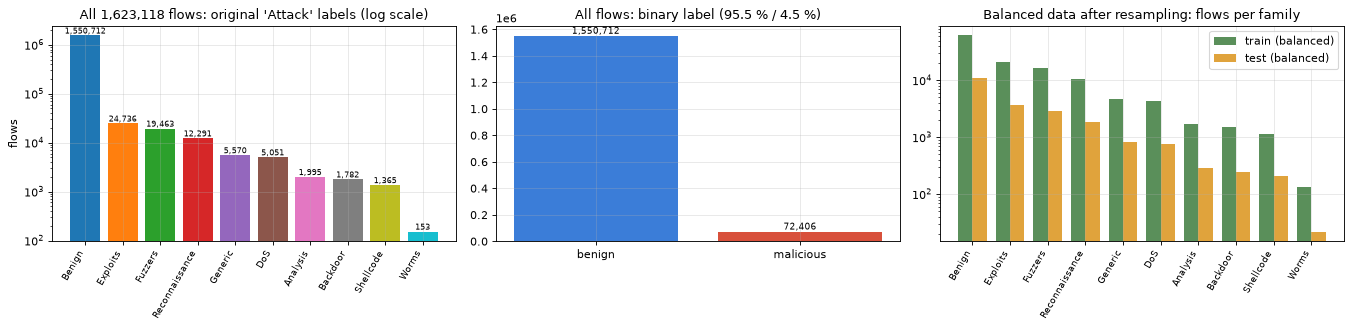

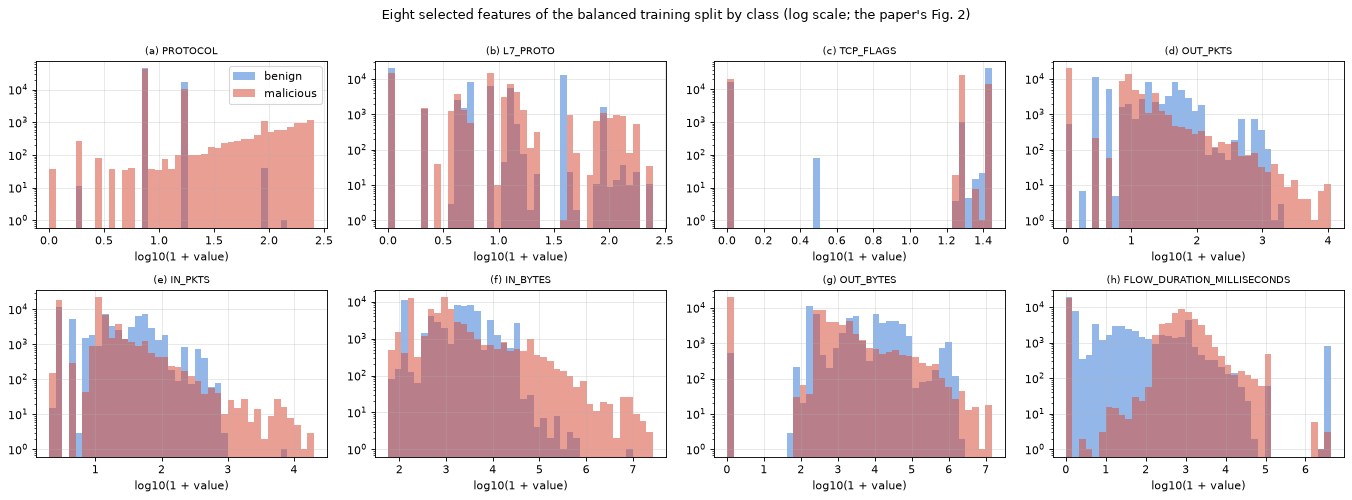

In [8]:
FAMS = list(FULL_ATTACK_COUNTS.index)
cmap = plt.get_cmap("tab10"); FAM_COL = {f: cmap(i) for i, f in enumerate(FAMS)}
BIN_COL = {0: "#3b7dd8", 1: "#d8503b"}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].bar(range(len(FAMS)), FULL_ATTACK_COUNTS.values, color=[FAM_COL[f] for f in FAMS]); ax[0].set_yscale("log")
ax[0].set_xticks(range(len(FAMS))); ax[0].set_xticklabels(FAMS, rotation=60, ha="right", fontsize=8)
for k, v in enumerate(FULL_ATTACK_COUNTS.values): ax[0].text(k, v, f"{v:,}", ha="center", va="bottom", fontsize=7)
ax[0].set_title("All 1,623,118 flows: original 'Attack' labels (log scale)"); ax[0].set_ylabel("flows")
ax[1].bar(["benign", "malicious"], [FULL_N - FULL_ATTACKS, FULL_ATTACKS], color=[BIN_COL[0], BIN_COL[1]]); ax[1].set_title("All flows: binary label (95.5 % / 4.5 %)")
for k, v in enumerate([FULL_N - FULL_ATTACKS, FULL_ATTACKS]): ax[1].text(k, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
w = 0.38; cnt_tr = TR.Attack.value_counts().reindex(FAMS).fillna(0); cnt_te = TE.Attack.value_counts().reindex(FAMS).fillna(0)
ax[2].bar(np.arange(len(FAMS)) - w / 2, cnt_tr.values, w, label="train (balanced)", color="#5a8f5a"); ax[2].bar(np.arange(len(FAMS)) + w / 2, cnt_te.values, w, label="test (balanced)", color="#e0a33c")
ax[2].set_xticks(range(len(FAMS))); ax[2].set_xticklabels(FAMS, rotation=60, ha="right", fontsize=8); ax[2].set_yscale("log"); ax[2].legend()
ax[2].set_title("Balanced data after resampling: flows per family")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(2, 4, figsize=(17, 6.2))
for k, f in enumerate(FEATURES):
    a = ax.ravel()[k]
    v = np.log10(1 + TR[f].values.astype(float))
    bins = np.linspace(v.min(), v.max() + 1e-9, 41)
    for lab, nm in ((0, "benign"), (1, "malicious")):
        a.hist(v[TR.Label.values == lab], bins=bins, alpha=0.55, color=BIN_COL[lab], label=nm)
    a.set_yscale("log"); a.set_title(f"({'abcdefgh'[k]}) {f}", fontsize=9); a.set_xlabel("log10(1 + value)")
ax[0, 0].legend()
plt.suptitle("Eight selected features of the balanced training split by class (log scale; the paper's Fig. 2)", y=1.0)
plt.tight_layout(); plt.show()

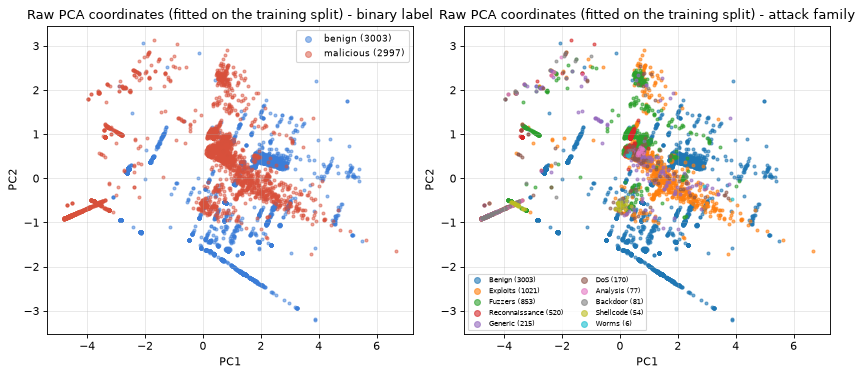

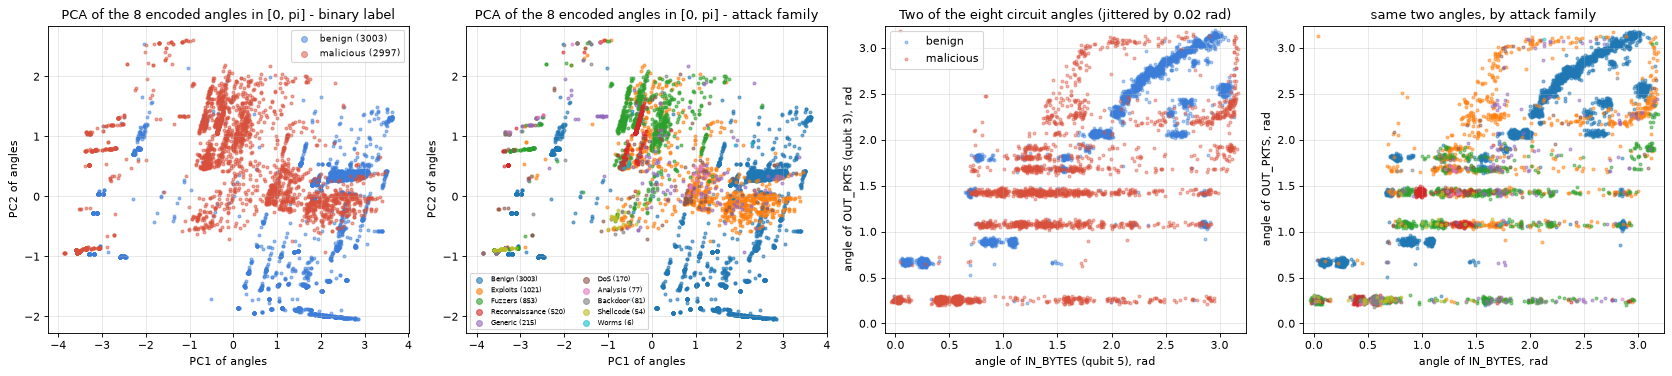

6000 random real training flows shown in each panel, coloured by their ground-truth labels. PCA explained variance (raw log-features): 0.77, (angles): 0.83


In [9]:
# 2-D scatter plots of REAL training flows coloured by ground-truth labels (labels only colour the points)
rs2 = np.random.default_rng(SEED); sel = rs2.choice(len(TR), 6000, replace=False)
sc = StandardScaler().fit(np.log1p(RAW_TR)); pca_raw = PCA(n_components=2, random_state=SEED).fit(sc.transform(np.log1p(RAW_TR)))      # fitted on the training split
P_raw = pca_raw.transform(sc.transform(np.log1p(RAW_TR[sel])))
pca_ang = PCA(n_components=2, random_state=SEED).fit(A_TR); P_ang = pca_ang.transform(A_TR[sel])
fam_sel, y_sel = TR.Attack.values[sel], Y_TR[sel]
def scatter_pair(ax_bin, ax_fam, P, title, xl, yl):
    for lab, nm in ((0, "benign"), (1, "malicious")):
        m = y_sel == lab; ax_bin.scatter(P[m, 0], P[m, 1], s=7, alpha=0.5, color=BIN_COL[lab], label=f"{nm} ({m.sum()})")
    for f in FAMS:
        m = fam_sel == f
        if m.any(): ax_fam.scatter(P[m, 0], P[m, 1], s=7, alpha=0.6, color=FAM_COL[f], label=f"{f} ({m.sum()})")
    for a in (ax_bin, ax_fam): a.set_xlabel(xl); a.set_ylabel(yl)
    ax_bin.set_title(title + " - binary label"); ax_fam.set_title(title + " - attack family"); ax_bin.legend(markerscale=2, fontsize=8); ax_fam.legend(markerscale=2, fontsize=6, ncol=2)

fig, ax = plt.subplots(1, 4, figsize=(21, 4.8))
scatter_pair(ax[0], ax[1], P_raw, "Raw PCA coordinates (fitted on the training split)", "PC1", "PC2")
ax[2].set_visible(False); ax[3].set_visible(False)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(21, 4.8))
scatter_pair(ax[0], ax[1], P_ang, "PCA of the 8 encoded angles in [0, pi]", "PC1 of angles", "PC2 of angles")
j1, j2 = FEATURES.index("IN_BYTES"), FEATURES.index("OUT_PKTS")
for lab, nm in ((0, "benign"), (1, "malicious")):
    m = y_sel == lab; ax[2].scatter(A_TR[sel][m, j1] + 0.02 * rs2.standard_normal(m.sum()), A_TR[sel][m, j2] + 0.02 * rs2.standard_normal(m.sum()), s=7, alpha=0.4, color=BIN_COL[lab], label=nm)
ax[2].set_xlabel("angle of IN_BYTES (qubit 5), rad"); ax[2].set_ylabel("angle of OUT_PKTS (qubit 3), rad"); ax[2].set_title("Two of the eight circuit angles (jittered by 0.02 rad)"); ax[2].set_xlim(-0.1, np.pi + 0.1); ax[2].set_ylim(-0.1, np.pi + 0.1); ax[2].legend()
for f in FAMS:
    m = fam_sel == f
    if m.any(): ax[3].scatter(A_TR[sel][m, j1] + 0.02 * rs2.standard_normal(m.sum()), A_TR[sel][m, j2] + 0.02 * rs2.standard_normal(m.sum()), s=7, alpha=0.5, color=FAM_COL[f])
ax[3].set_xlabel("angle of IN_BYTES, rad"); ax[3].set_ylabel("angle of OUT_PKTS, rad"); ax[3].set_title("same two angles, by attack family"); ax[3].set_xlim(-0.1, np.pi + 0.1); ax[3].set_ylim(-0.1, np.pi + 0.1)
plt.tight_layout(); plt.show()
print("6000 random real training flows shown in each panel, coloured by their ground-truth labels. PCA explained variance (raw log-features): %.2f, (angles): %.2f" % (pca_raw.explained_variance_ratio_.sum(), pca_ang.explained_variance_ratio_.sum()))

**What the plots show.** The malicious class is dominated by Exploits, Fuzzers and Reconnaissance flows (see the bar charts). In the raw PCA plane and in the angle plane benign and malicious flows overlap in a large central region, and both classes form many narrow clusters or bands (flows with identical packet counts or TCP flags collapse onto the same coordinates; in the two-angle panel the malicious flows lie in horizontal bands at fixed packet-count angles over the whole byte range, whereas many benign flows sit along a diagonal at high packet and byte percentiles). The eight angles are the *only* input of the quantum model: the information the circuit can use is exactly what survives the percentile encoding, and every classifier below receives the same angles.

## 4. Classical baselines on identical inputs

The same training / test flows are given to classical models in two forms: the **eight encoded angles** (exactly what the QNN sees) and the **eight raw features**. Models: random forest and extra trees (100 trees; the original NF-UNSW-NB15 paper used extra trees), and an RBF SVM (trained on the first `SVC_N` training flows, because an exact SVM on 120k flows is slow). Positive class = malicious. These numbers are the context for the paper's claim that the QNN is "on par with classical ML".

In [10]:
def metrics(y, pred):
    return dict(acc=accuracy_score(y, pred), prec=precision_score(y, pred, zero_division=0), rec=recall_score(y, pred), f1=f1_score(y, pred))
def timed(fn):
    t = time.perf_counter(); r = fn(); return r, time.perf_counter() - t

BASE = []
for in_name, (Xa, Xb) in {"8 encoded angles": (A_TR, A_TE), "8 raw features": (RAW_TR, RAW_TE)}.items():
    for name, mk, n in [("RandomForest(100)", lambda: RandomForestClassifier(100, random_state=SEED, n_jobs=2), None),
                        ("ExtraTrees(100)", lambda: ExtraTreesClassifier(100, random_state=SEED, n_jobs=2), None),
                        (f"SVC(rbf) on {SVC_N:,} flows", lambda: SVC(kernel="rbf", C=1.0, gamma="scale"), SVC_N)]:
        if in_name == "8 raw features" and name.startswith("ExtraTrees"): continue        # keep the run short: one forest is enough on raw features
        Xf = Xa if n is None else Xa[:n]; yf = Y_TR if n is None else Y_TR[:n]
        if name.startswith("SVC") and in_name == "8 raw features":
            s_ = StandardScaler().fit(np.log1p(Xf)); fx, tx = s_.transform(np.log1p(Xf)), s_.transform(np.log1p(Xb))      # SVC needs scaled input
        else: fx, tx = Xf, Xb
        m, t_fit = timed(lambda: mk().fit(fx, yf)); pr, t_pr = timed(lambda: m.predict(tx))
        BASE.append(dict(inputs=in_name, model=name, seconds=round(t_fit + t_pr, 1), **{k: round(v, 4) for k, v in metrics(Y_TE, pr).items()}))
BASE = pd.DataFrame(BASE); display(BASE)
F1_RF_ANGLES = float(BASE[(BASE.inputs == "8 encoded angles") & (BASE.model == "RandomForest(100)")].f1.iloc[0])
F1_ET_ANGLES = float(BASE[(BASE.inputs == "8 encoded angles") & (BASE.model == "ExtraTrees(100)")].f1.iloc[0])

,inputs,model,seconds,acc,prec,rec,f1
0,8 encoded angles,RandomForest(100),76.1,0.9883,0.9799,0.9969,0.9883
1,8 encoded angles,ExtraTrees(100),31.4,0.9871,0.9801,0.9943,0.9871
2,8 encoded angles,"SVC(rbf) on 5,000 flows",10.4,0.9612,0.9566,0.9657,0.9611
3,8 raw features,RandomForest(100),120.8,0.9876,0.9804,0.9949,0.9876
4,8 raw features,"SVC(rbf) on 5,000 flows",43.2,0.9511,0.9165,0.9918,0.9527


## 5. The "Simple" QNN: an exact fast simulator, checked against Qiskit

**The circuit.** Qubits 0 to 7 hold the eight feature angles (`Rx(theta_j)|0>`); qubit 8 is the readout qubit, prepared in `|->` (an `X` then an `H`). A layer of type `XY` applies `Rxx(t)` between feature qubit `j` and the readout qubit for `j = 0..7`, then `Ryy(t)` for `j = 0..7`; each of the 16 gates has its own trainable angle. After the last layer the readout qubit is measured in the X basis; the output is `<X_readout>` in `[-1, 1]` (the paper's certainty factor for the "Simple" architecture) and the prediction is "malicious" when it is positive.

**Why a custom simulator.** The paper trained with TensorFlow Quantum on a GPU-less laptop-class budget of thousands of epochs; a generic gate-by-gate state-vector simulator needs about 0.3 s per mini-batch of 32 flows for 6 layers on this CPU, which would make even one epoch (3,800 batches) impractical. The structure of the circuit allows a much faster *exact* simulation: the eight `Rxx` gates of a block all commute with each other, so a whole block is **diagonal in the X eigenbasis** of the nine qubits (the phase of a basis state is `exp(-i/2 * sum_j t_j x_j x_readout)` with `x = +-1`), and the `Ryy` block is diagonal in the Y eigenbasis; likewise `Rzz` blocks in the Z basis. A layer is therefore two element-wise phase multiplications and two changes of basis, each a tensor power of a 2x2 matrix that is applied as one 32x32 and one 16x16 matrix product. Gradients use the adjoint method (exact, one backward sweep). The cells below *assert* that (a) the output equals Qiskit's `Statevector` of the circuit drawn in the next section for several layer types and depths and (b) the gradients equal finite differences.

Layer types are written as strings: `"XY"` = `Rxx` block then `Ryy` block; `"ZXY"` = `Rzz`, `Rxx`, `Ryy` blocks (the paper's "ZZ XX YY"); `"ZX"`, `"ZY"` likewise.

In [11]:
NQ, NT, DIM = 8, 9, 512
_idx = np.arange(DIM)
_bits = np.array([(_idx >> (NQ - q)) & 1 for q in range(NT)])             # qubit q of basis state idx; qubit 0 most significant, readout (qubit 8) least significant
_sgn = 1 - 2 * _bits                                                       # +-1 eigenvalue of X, Y or Z in its own eigenbasis (index 0 = +1)
G_SIGN = (_sgn[:NQ] * _sgn[NQ][None, :]).astype(np.float64)               # (8, 512): eigenvalue of P_j (x) P_readout
H1 = np.array([[1, 1], [1, -1]], complex) / np.sqrt(2)
V1 = {"Z": np.eye(2, dtype=complex), "X": H1, "Y": np.array([[1, -1j], [1, 1j]], complex) / np.sqrt(2)}   # rows = <eigenstate|
def _kron_pow(M, n):
    K = np.array([[1]], complex)
    for _ in range(n): K = np.kron(K, M)
    return K
_TC = {}
def basis_change(a, A, B):
    # amplitudes (n, 512) in the eigenbasis of Pauli A -> eigenbasis of Pauli B: tensor power of V_B V_A^dagger, applied as a 32x32 (5 qubits) and a 16x16 (4 qubits) matrix
    if A == B: return a
    if (A, B) not in _TC:
        M = V1[B] @ V1[A].conj().T
        _TC[(A, B)] = (_kron_pow(M, 5).astype(np.complex64), _kron_pow(M, 4).T.astype(np.complex64))
    K5, K4T = _TC[(A, B)]
    n = a.shape[0]
    return np.matmul(np.matmul(K5, a.reshape(n, 32, 16)), K4T).reshape(n, DIM)
def product_state(X):
    # computational-basis state: feature qubit j = Rx(x_j)|0>, readout = |->
    n = X.shape[0]; c = np.cos(X / 2).astype(np.complex64); s = (-1j * np.sin(X / 2)).astype(np.complex64)
    st = np.ones((n, 1), np.complex64)
    for j in range(NQ):
        st = (st[:, :, None] * np.stack([c[:, j], s[:, j]], 1)[:, None, :]).reshape(n, -1)
    ro = (np.array([1, -1]) / np.sqrt(2)).astype(np.complex64)
    return (st[:, :, None] * ro[None, None, :]).reshape(n, DIM)
def parse_type(t):
    return {"XY": ["X", "Y"], "ZXY": ["Z", "X", "Y"], "ZX": ["Z", "X"], "ZY": ["Z", "Y"]}[t]
def make_blocks(L, layer_type="XY"):
    return [p for _ in range(L) for p in parse_type(layer_type)]
def phases(theta_block):
    return np.exp(-0.5j * (theta_block @ G_SIGN)).astype(np.complex64)
def simple_forward(X, theta, blocks, keep=False):
    th = theta.reshape(len(blocks), NQ); a = product_state(X); cur = "Z"; store = []
    for k, P in enumerate(blocks):
        a = basis_change(a, cur, P); cur = P
        a = a * phases(th[k])
        if keep: store.append(a)
    a = basis_change(a, cur, "X")
    E = (np.abs(a) ** 2) @ _sgn[NQ].astype(np.float32)               # <X_readout>
    return (E, a, store) if keep else E
def simple_fwd_bwd(X, y, theta, blocks):
    # hinge loss mean(max(0, 1 - y E)) and its exact gradient (adjoint method)
    th = theta.reshape(len(blocks), NQ)
    E, aX, store = simple_forward(X, theta, blocks, keep=True)
    w = np.where(1 - y * E > 0, -y, 0.0) / len(y)
    lam = aX * _sgn[NQ].astype(np.float32); cur = "X"; grad = np.zeros((len(blocks), NQ))
    for k in range(len(blocks) - 1, -1, -1):
        P = blocks[k]
        lam = basis_change(lam, cur, P); cur = P
        Q = (w[:, None].astype(np.float32) * np.conj(lam) * store[k]).sum(0)
        grad[k] = np.imag(G_SIGN @ Q)
        lam = lam * np.conj(phases(th[k]))
    return E, grad.ravel(), float(np.mean(np.maximum(0, 1 - y * E)))

class SimpleQNN:
    # the paper's "Simple" architecture: L layers of a given layer type
    def __init__(self, L, layer_type="XY"):
        self.L, self.layer_type = L, layer_type; self.blocks = make_blocks(L, layer_type); self.n_params = NQ * len(self.blocks)
        self.name = f"Simple {L}x{layer_type}"
    def predict(self, X, theta, bs=2048):
        return np.concatenate([simple_forward(X[i:i + bs], theta, self.blocks) for i in range(0, len(X), bs)])
    def fwd_bwd(self, X, y, theta):
        return simple_fwd_bwd(X, y, theta, self.blocks)

# --- check 1: gradients equal finite differences (all layer types)
rng_t = np.random.default_rng(0); Xb = rng_t.uniform(0, np.pi, (16, NQ)); yb = rng_t.choice([-1.0, 1.0], 16); worst = 0
for lt in ("XY", "ZX", "ZY", "ZXY"):
    m = SimpleQNN(2, lt); th = rng_t.uniform(0, 2 * np.pi, m.n_params); _, g, _ = m.fwd_bwd(Xb, yb, th)
    Lf = lambda t: np.mean(np.maximum(0, 1 - yb * m.predict(Xb, t)))
    fd = np.array([(Lf(th + 1e-2 * np.eye(m.n_params)[k]) - Lf(th - 1e-2 * np.eye(m.n_params)[k])) / 2e-2 for k in range(m.n_params)])
    worst = max(worst, np.abs(fd - g).max() / np.abs(g).max())
print("largest relative gradient error against finite differences: %.1e" % worst); assert worst < 1e-3

largest relative gradient error against finite differences: 8.7e-05


## Quantum Circuit Architecture

Everything that is trained or evaluated in this notebook is a gate-based circuit, and each distinct architecture is drawn below from the Qiskit circuit object that the equivalence checks run:

1. **Simple, 6 layers of type XY** (the paper's best noiseless network): 8 `Rx` encodings, `X` + `H` on the readout qubit, 96 trainable two-qubit Pauli rotations (48 `Rxx`, 48 `Ryy`), `H` for the X-basis measurement.
2. **Simple, 2 layers of type XY** (the network the authors could run on Aria-1): 32 trainable gates.
3. **TTN** (tree tensor network) and 4. **QCNN**: the rivals of Table 2, built from *generic two-qubit gates = two generic one-qubit gates (`Rz Ry Rz` each) followed by one CNOT* (paper Fig. 6). Their wiring is not readable in the PDF text we have (Fig. 5 is an image), so the wiring below is a `# CHOICE:` reconstruction from Grant et al. (TTN) and Cong et al. (QCNN), and **MERA is not reproduced**.

Assumptions where the paper omits circuit details: input angles are loaded on `|0...0>` by `Rx` (as stated); the readout qubit is prepared `X` then `H` (|->, as stated); weights are initialised uniformly in `[0, 2 pi]`; in the "Simple" circuits a layer applies the eight `Rxx` gates in feature-qubit order then the eight `Ryy` gates; the output of TTN / QCNN is `<Z>` of the last remaining qubit (pooling keeps the second qubit of each pair).

Simple 6xXY: 9 qubits | depth 100 (with measurement) | trainable parameters 96 | input angles 8 | gates {'rxx': 48, 'ryy': 48, 'barrier': 13, 'rx': 8, 'h': 2, 'x': 1}


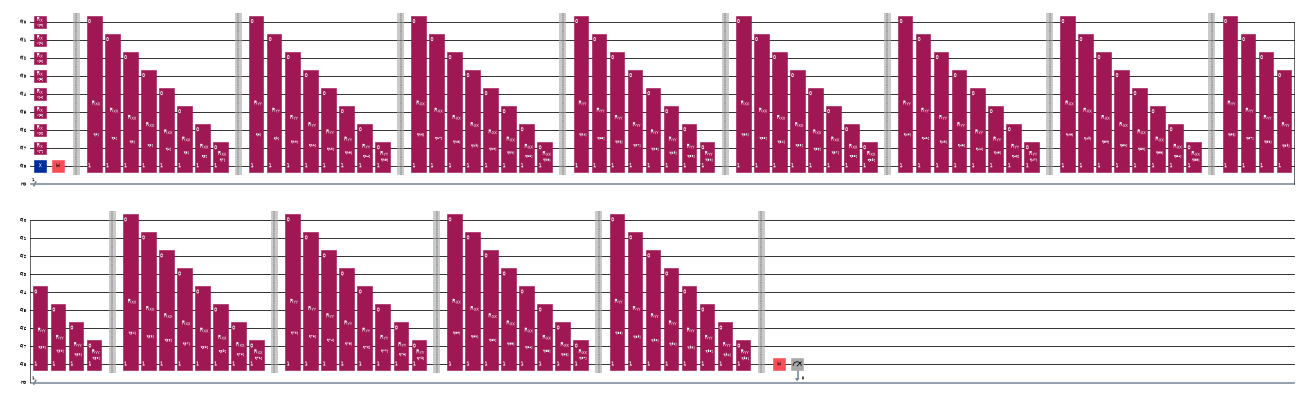

Simple 2xXY: 9 qubits | depth 36 (with measurement) | trainable parameters 32 | input angles 8 | gates {'rxx': 16, 'ryy': 16, 'rx': 8, 'barrier': 5, 'h': 2, 'x': 1}


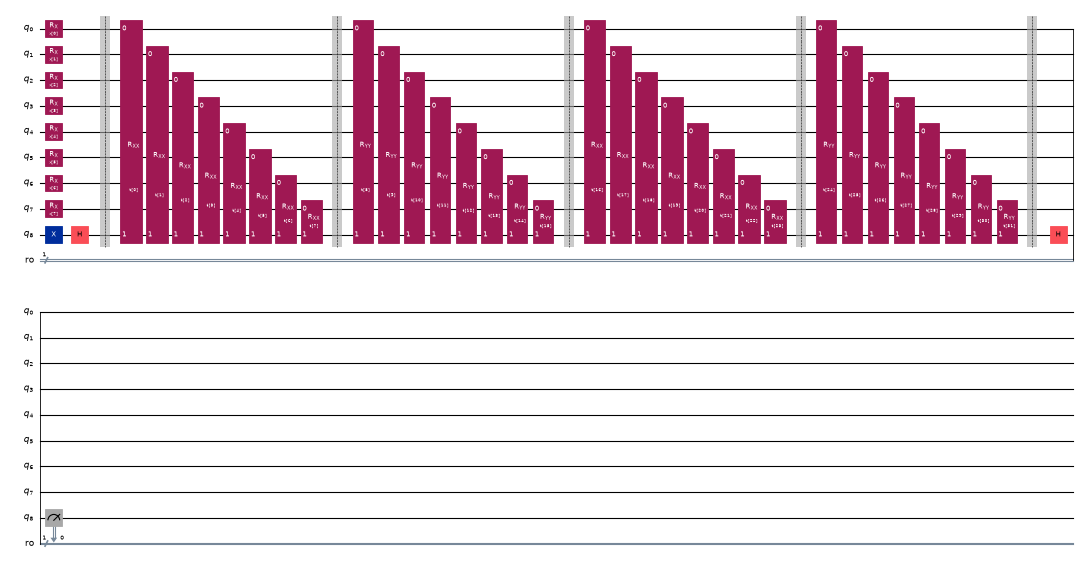

In [12]:
def simple_qiskit(L, layer_type="XY"):
    # the executed circuit: encoding, readout preparation, trainable Pauli-rotation layers, X-basis measurement (H then measure)
    blocks = make_blocks(L, layer_type)
    x = ParameterVector("x", NQ); t = ParameterVector("t", NQ * len(blocks))
    qc = QuantumCircuit(NT, name=f"Simple {L}x{layer_type}")
    for j in range(NQ): qc.rx(x[j], j)
    qc.x(NQ); qc.h(NQ); qc.barrier()
    k = 0
    for P in blocks:
        for j in range(NQ):
            {"X": qc.rxx, "Y": qc.ryy, "Z": qc.rzz}[P](t[k], j, NQ); k += 1
        qc.barrier()
    qc.h(NQ)
    return qc, x, t
def bind(qc, x, t, xv, tv):
    return qc.assign_parameters({**dict(zip(x, xv)), **dict(zip(t, tv))})
def simple_expectation_qiskit(qc, x, t, xv, tv):
    p = Statevector(bind(qc, x, t, xv, tv)).probabilities([NQ]); return p[0] - p[1]      # P(readout=0) - P(readout=1) after H = <X>

for L, lt in ((6, "XY"), (2, "XY")):
    qc, xp, tp = simple_qiskit(L, lt); qm = qc.copy(); qm.add_register(ClassicalRegister(1, "ro")); qm.measure(NQ, 0)      # only the readout qubit is measured
    print(f"Simple {L}x{lt}: {qc.num_qubits} qubits | depth {qm.depth()} (with measurement) | trainable parameters {len(tp)} | input angles {len(xp)} | gates {dict(qc.count_ops())}")
    display(qm.draw("mpl", fold=40 if L == 2 else 70, scale=0.5 if L == 2 else 0.35)); plt.close("all")

In [13]:
# equivalence of the fast simulator with Qiskit's Statevector (executed circuits), several depths and layer types
rng_t = np.random.default_rng(1); worst = 0
for L, lt in ((6, "XY"), (2, "XY"), (1, "ZXY"), (2, "ZX"), (2, "ZY")):
    m = SimpleQNN(L, lt); qc, xp, tp = simple_qiskit(L, lt); th = rng_t.uniform(0, 2 * np.pi, m.n_params); Xs = rng_t.uniform(0, np.pi, (4, NQ))
    ref = np.array([simple_expectation_qiskit(qc, xp, tp, Xs[i], th) for i in range(4)]); got = m.predict(Xs, th)
    worst = max(worst, np.abs(ref - got).max())
print("largest |Qiskit Statevector - fast simulator| over 5 architectures x 4 random inputs: %.1e" % worst)
assert worst < 5e-6, "simulator and Qiskit disagree"

largest |Qiskit Statevector - fast simulator| over 5 architectures x 4 random inputs: 1.7e-07


### Generic two-qubit-gate networks: TTN and QCNN (Table 2 rivals)

A *generic* two-qubit gate is modelled as in the paper's Fig. 6: two generic one-qubit gates (`Rz Ry Rz`, 3 angles each) followed by one CNOT, i.e. 6 trainable angles. **TTN:** binary tree over the eight feature qubits (pairs 0-1, 2-3, 4-5, 6-7, then the surviving qubits pairwise, then the last pair), 7 generic gates = 42 parameters, output `<Z>` of the last qubit. **QCNN:** per level one shared convolution gate applied to neighbouring pairs and a second staggered set, then a shared pooling gate that keeps one qubit of each pair (gates with the same index share parameters, as in the paper), 3 levels, 36 parameters. A small exact simulator with an adjoint gradient runs them; it is asserted equal to Qiskit as well.

TTN: 8 qubits | depth 14 | trainable parameters 42 | gates {'rz': 28, 'ry': 14, 'rx': 8, 'cx': 7, 'barrier': 1}


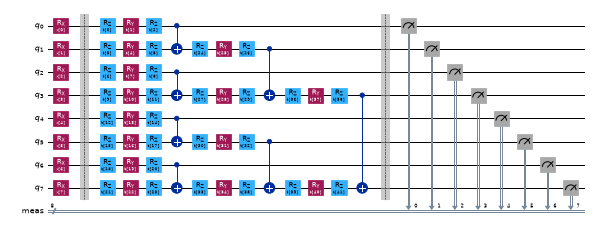

QCNN: 8 qubits | depth 34 | trainable parameters 36 | gates {'rz': 72, 'ry': 36, 'cx': 18, 'rx': 8, 'barrier': 1}


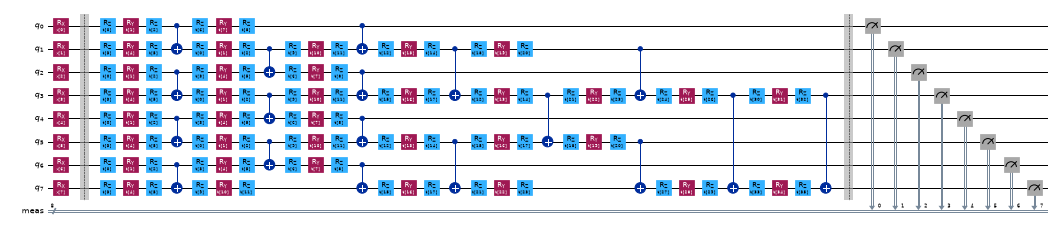

gradient error vs finite differences 9.2e-05 | |Qiskit - simulator| 1.3e-07


In [14]:
class GenericQNN:
    # state-vector simulator for circuits of Pauli rotations exp(-i theta P / 2) and CNOTs on n qubits; inputs Rx(x_j)|0>; output <Z> of one qubit; adjoint gradients
    def __init__(self, n, ops, n_params, out_qubit, name):
        self.n, self.ops, self.n_params, self.out, self.name = n, ops, n_params, out_qubit, name
        D = 2 ** n; idx = np.arange(D); bit = lambda q: (idx >> (n - 1 - q)) & 1; self.perm, self.mult = {}, {}
        for op in ops:
            if op[0] == "R":
                _, P, q, k = op
                if (P, q) in self.perm: continue
                m = 1 << (n - 1 - q)
                if P == "Z": self.perm[(P, q)] = idx; self.mult[(P, q)] = (1 - 2 * bit(q)).astype(np.complex64)
                elif P == "X": self.perm[(P, q)] = idx ^ m; self.mult[(P, q)] = np.ones(D, np.complex64)
                else: self.perm[(P, q)] = idx ^ m; self.mult[(P, q)] = np.where(bit(q) == 0, -1j, 1j).astype(np.complex64)
            else:
                self.perm[("CX", op[1], op[2])] = np.where(bit(op[1]) == 1, idx ^ (1 << (n - 1 - op[2])), idx)
        self.zout = (1 - 2 * bit(out_qubit)).astype(np.float32)
    def _init(self, X):
        c = np.cos(X / 2).astype(np.complex64); s = (-1j * np.sin(X / 2)).astype(np.complex64); st = np.ones((X.shape[0], 1), np.complex64)
        for j in range(self.n): st = (st[:, :, None] * np.stack([c[:, j], s[:, j]], 1)[:, None, :]).reshape(X.shape[0], -1)
        return st
    def _G(self, st, P, q): return st[:, self.perm[(P, q)]] * self.mult[(P, q)]
    def _app(self, st, op, th):
        if op[0] == "R": return np.float32(np.cos(th / 2)) * st - np.complex64(1j * np.sin(th / 2)) * self._G(st, op[1], op[2])
        return st[:, self.perm[("CX", op[1], op[2])]]
    def _forward(self, X, theta):
        st = self._init(X)
        for op in self.ops: st = self._app(st, op, theta[op[3]] if op[0] == "R" else 0.0)
        return (np.abs(st) ** 2) @ self.zout, st
    def predict(self, X, theta, bs=4096):
        return np.concatenate([self._forward(X[i:i + bs], theta)[0] for i in range(0, len(X), bs)])
    def fwd_bwd(self, X, y, theta):
        E, st = self._forward(X, theta); w = np.where(1 - y * E > 0, -y, 0.0) / len(y); lam = st * self.zout; grad = np.zeros(self.n_params)
        for op in reversed(self.ops):
            if op[0] == "R":
                grad[op[3]] += np.sum(w * np.imag(np.sum(np.conj(lam) * self._G(st, op[1], op[2]), axis=1)))
                st = self._app(st, op, -theta[op[3]]); lam = self._app(lam, op, -theta[op[3]])
            else:
                st = self._app(st, op, 0.0); lam = self._app(lam, op, 0.0)
        return E, grad, float(np.mean(np.maximum(0, 1 - y * E)))
    def to_qiskit(self, theta=None):
        x = ParameterVector("x", self.n); t = ParameterVector("t", self.n_params); qc = QuantumCircuit(self.n, name=self.name)
        for j in range(self.n): qc.rx(x[j], j)
        qc.barrier()
        for op in self.ops:
            if op[0] == "R": getattr(qc, "r" + op[1].lower())(t[op[3]], op[2])
            else: qc.cx(op[1], op[2])
        return qc, x, t

def _u3(q, k): return [("R", "Z", q, k), ("R", "Y", q, k + 1), ("R", "Z", q, k + 2)]
def _gate2(a, b, k): return _u3(a, k) + _u3(b, k + 3) + [("CX", a, b)]             # two generic one-qubit gates + one CNOT (paper Fig. 6)
def build_ttn(n=NQ):
    ops, k, level = [], 0, list(range(n))
    while len(level) > 1:
        nxt = []
        for a, b in zip(level[0::2], level[1::2]): ops += _gate2(a, b, k); k += 6; nxt.append(b)
        level = nxt
    return GenericQNN(n, ops, k, level[0], "TTN")
def build_qcnn(n=NQ):
    ops, level, layer, shared, k = [], list(range(n)), 0, {}, 0
    def gate(a, b, nm):
        nonlocal k
        if nm not in shared: shared[nm] = k; k += 6
        return _gate2(a, b, shared[nm])
    while len(level) > 1:
        for a, b in zip(level[0::2], level[1::2]): ops += gate(a, b, f"conv{layer}")
        for a, b in zip(level[1::2], level[2::2]): ops += gate(a, b, f"conv{layer}")
        nxt = []
        for a, b in zip(level[0::2], level[1::2]): ops += gate(a, b, f"pool{layer}"); nxt.append(b)
        level = nxt; layer += 1
    return GenericQNN(n, ops, k, level[0], "QCNN")

TTN, QCNN = build_ttn(), build_qcnn()
rng_t = np.random.default_rng(2); worst_g = worst_e = 0
for m in (TTN, QCNN):
    th = rng_t.uniform(0, 2 * np.pi, m.n_params); Xb = rng_t.uniform(0, np.pi, (12, NQ)); yb = rng_t.choice([-1.0, 1.0], 12)
    _, g, _ = m.fwd_bwd(Xb, yb, th); Lf = lambda t: np.mean(np.maximum(0, 1 - yb * m.predict(Xb, t)))
    fd = np.array([(Lf(th + 1e-2 * np.eye(m.n_params)[k]) - Lf(th - 1e-2 * np.eye(m.n_params)[k])) / 2e-2 for k in range(m.n_params)]); worst_g = max(worst_g, np.abs(fd - g).max() / np.abs(g).max())
    qc, xp, tp = m.to_qiskit(); z = SparsePauliOp("I" * (m.n - 1 - m.out) + "Z" + "I" * m.out)
    for i in range(3):
        ref = Statevector(qc.assign_parameters({**dict(zip(xp, Xb[i])), **dict(zip(tp, th))})).expectation_value(z).real
        worst_e = max(worst_e, abs(ref - m.predict(Xb[i:i + 1], th)[0]))
    qm = qc.copy(); qm.measure_all()
    print(f"{m.name}: {qc.num_qubits} qubits | depth {qm.depth()} | trainable parameters {m.n_params} | gates {dict(qc.count_ops())}")
    display(qm.draw("mpl", fold=60, scale=0.45)); plt.close("all")
print("gradient error vs finite differences %.1e | |Qiskit - simulator| %.1e" % (worst_g, worst_e)); assert worst_g < 1e-3 and worst_e < 5e-6

**Reading the drawings.** The first two figures are the "Simple" networks: the left block is the data loading (one `Rx` per feature qubit), then the readout preparation (`X`, `H`), then the trainable layers in which every gate connects one feature qubit to the readout qubit (the bottom wire) - the star-shaped connectivity that needs an all-to-all machine - and finally `H` plus a measurement of the readout qubit. The last two are the TTN and QCNN networks built from generic gates (three-angle `Rz Ry Rz` single-qubit blocks and a CNOT).

## 6. Training

**Loss and labels.** As in the paper: hinge loss on labels `+1` (malicious) and `-1` (benign), the network output is `E = <X_readout>`; accuracy and F1 use the sign of `E` (positive class = malicious).

**Two ways of training the 6-layer network.**
1. *Paper hyper-parameters*: SGD without momentum, learning rate 0.02 with Keras-style decay `lr / (1 + 0.001 * step)`, batch 32, random initial weights, epochs over the training pool (the number of epochs is not stated; see the configuration cell for ours). The checkpoint with the best validation F1 is evaluated on the test set.
2. *Tuned multi-start Adam* (our addition, `# CHOICE:`): the circuit's output is a trigonometric function of ~100 angles and a single random start often lands in a poor valley (the printed `start validation F1s` below differ by several F1 points between random starts), which a much larger budget and grid search, as in the paper, would average out. We therefore train `starts` networks from different random weights for a few hundred steps (Adam, batch `sel_bs`), keep the one with the best **validation** F1 and continue it with exponentially decaying learning rate (`lr0 -> lr1`) and a larger batch, keeping the best-validation checkpoint. Only training and validation flows are used for these choices; the test flows are used once at the end.

In [15]:
def f1_from_E(s, E): return f1_score(s > 0, E > 0)
class Sampler:
    def __init__(self, n, bs, rng): self.n, self.bs, self.rng, self.perm, self.pos = n, bs, rng, rng.permutation(n), 0
    def next(self):
        if self.pos + self.bs > self.n: self.perm, self.pos = self.rng.permutation(self.n), 0
        b = self.perm[self.pos:self.pos + self.bs]; self.pos += self.bs; return b

def train_model(model, Xtr, str_, Xva, sva, *, optimizer="adam", starts=1, sel_iters=0, sel_bs=64, iters=300, bs=128, lr0=0.02, lr1=0.002,
                decay=None, epochs=None, max_iters=None, eval_every=100, seed=SEED, label=""):
    # multi-start phase (Adam, lr 0.05 -> 0.02) then main phase; returns the best-validation parameters and the history
    rng = np.random.default_rng(seed); hist = []; t0 = time.perf_counter(); n_it = 0
    def adam_phase(th, st, n, b, a0, a1, phase, start_id):
        nonlocal n_it
        off = sel_iters if phase == "main" else 0           # x axis of the learning-curve plot: local step, main phase continues after the selection phase
        m, v, t = st if st else (np.zeros_like(th), np.zeros_like(th), 0)
        smp = Sampler(len(Xtr), b, rng); best = (-1.0, th.copy())
        for it in range(1, n + 1):
            idx = smp.next(); _, g, loss = model.fwd_bwd(Xtr[idx], str_[idx], th); t += 1; n_it += 1
            lr = a0 * (a1 / a0) ** (it / n)
            m = 0.9 * m + 0.1 * g; v = 0.999 * v + 0.001 * g * g
            th = th - lr * (m / (1 - 0.9 ** t)) / (np.sqrt(v / (1 - 0.999 ** t)) + 1e-7)
            if it % eval_every == 0 or it == n:
                f = f1_from_E(sva, model.predict(Xva, th)); hist.append(dict(step=n_it, x=it + off, val_f1=f, loss=loss, phase=phase, start=start_id))
                if f > best[0]: best = (f, th.copy())
        return th, (m, v, t), best
    if optimizer == "sgd":
        th = rng.uniform(0, 2 * np.pi, model.n_params); smp = Sampler(len(Xtr), bs, rng)
        total = max_iters or int(epochs * (len(Xtr) // bs)); best = (-1.0, th.copy())
        for it in range(1, total + 1):
            idx = smp.next(); _, g, loss = model.fwd_bwd(Xtr[idx], str_[idx], th)
            th = th - lr0 / (1 + (decay or 0.0) * it) * g
            if it % eval_every == 0 or it == total:
                f = f1_from_E(sva, model.predict(Xva, th)); hist.append(dict(step=it, x=it, val_f1=f, loss=loss, phase="sgd", start=0))
                if f > best[0]: best = (f, th.copy())
        return dict(theta=best[1], val_f1=best[0], hist=pd.DataFrame(hist), seconds=time.perf_counter() - t0, steps=total, label=label)
    cands = []
    for s_ in range(starts):
        th = rng.uniform(0, 2 * np.pi, model.n_params)
        if sel_iters:
            th, st, b = adam_phase(th, None, sel_iters, sel_bs, 0.05, 0.02, "select", s_); cands.append((b[0], b[1], st))
        else: cands.append((-1.0, th, None))
    cands.sort(key=lambda c: -c[0]); f0, th, st = cands[0]
    th2, st2, b2 = adam_phase(th, st, iters, bs, lr0, lr1, "main", -1)
    best = b2 if b2[0] >= f0 else (f0, th)
    return dict(theta=best[1], val_f1=best[0], hist=pd.DataFrame(hist), seconds=time.perf_counter() - t0, steps=n_it, label=label,
                start_scores=[round(float(c[0]), 4) for c in cands])

def evaluate(model, theta, X, y_bin, s_pm):
    E = model.predict(X, theta); pred = (E > 0).astype(int)
    return dict(E=E, pred=pred, **metrics(y_bin, pred), cm=confusion_matrix(y_bin, pred, labels=[0, 1]))

# training pool and validation set in angle space (+-1 labels)
A_FIT, S_FIT = A_TR[FIT_IDX], S_TR[FIT_IDX]
A_VAL, S_VAL = A_TR[VAL_IDX], S_TR[VAL_IDX]
EV_IDX = np.random.default_rng(SEED + 7).choice(len(A_TE), EVAL_N, replace=False)      # test subset for the secondary experiments (standard error of an F1 near 0.8 is about 0.005)
A_EV, Y_EV, S_EV = A_TE[EV_IDX], Y_TE[EV_IDX], S_TE[EV_IDX]
print("QNN training pool", A_FIT.shape, "| validation", A_VAL.shape, "| test", A_TE.shape, "| secondary-experiment test subset", A_EV.shape)

QNN training pool (20000, 8) | validation (4000, 8) | test (21722, 8) | secondary-experiment test subset (6000, 8)


### 6.1 The 6-layer XY network with the paper's hyper-parameters (SGD, lr 0.02, decay 0.001, batch 32)

In [16]:
M6 = SimpleQNN(6, "XY")
RES = {}
RES["6L paper-SGD"] = train_model(M6, A_FIT, S_FIT, A_VAL, S_VAL, optimizer="sgd", bs=PAPER_SGD["bs"], lr0=PAPER_SGD["lr0"], decay=PAPER_SGD["decay"],
                                  epochs=PAPER_SGD["epochs"], max_iters=PAPER_SGD["max_iters"], eval_every=PAPER_SGD["eval_every"], seed=SEED, label="6L XY, paper SGD")
r = RES["6L paper-SGD"]; r["test"] = evaluate(M6, r["theta"], A_TE, Y_TE, S_TE)
print(f"{r['label']}: {r['steps']:,} SGD steps ({r['seconds']:.0f} s) | best validation F1 {r['val_f1']:.4f} | TEST F1 {r['test']['f1']:.4f}, accuracy {r['test']['acc']:.4f}")

6L XY, paper SGD: 1,200 SGD steps (385 s) | best validation F1 0.8642 | TEST F1 0.8524, accuracy 0.8644


### 6.2 The 6-layer XY network with tuned multi-start Adam

In [17]:
RES["6L tuned"] = train_model(M6, A_FIT, S_FIT, A_VAL, S_VAL, optimizer="adam", seed=SEED, label="6L XY, tuned multi-start Adam", **TUNED_6L)
r = RES["6L tuned"]; r["test"] = evaluate(M6, r["theta"], A_TE, Y_TE, S_TE)
print(f"{r['label']}: {r['steps']:,} Adam steps ({r['seconds']:.0f} s) | start validation F1s {r['start_scores']} | best validation F1 {r['val_f1']:.4f} | TEST F1 {r['test']['f1']:.4f}, accuracy {r['test']['acc']:.4f}")
THETA_6L = r["theta"]

6L XY, tuned multi-start Adam: 600 Adam steps (424 s) | start validation F1s [0.8775, 0.785, 0.7155] | best validation F1 0.8775 | TEST F1 0.8753, accuracy 0.8858


### 6.3 The 2-layer XY network (the size the authors could run on Aria-1)

In [18]:
M2 = SimpleQNN(2, "XY"); RES["2L tuned"] = []
for sd in SEEDS_2L:
    rr = train_model(M2, A_FIT, S_FIT, A_VAL, S_VAL, optimizer="adam", seed=sd, label=f"2L XY, seed {sd}", **TUNED_2L); rr["test"] = evaluate(M2, rr["theta"], A_TE, Y_TE, S_TE); RES["2L tuned"].append(rr)
    print(f"{rr['label']}: {rr['seconds']:.0f} s | start validation F1s {rr['start_scores']} | validation F1 {rr['val_f1']:.4f} | TEST F1 {rr['test']['f1']:.4f}")
BEST2 = max(RES["2L tuned"], key=lambda r: r["val_f1"]); THETA_2L = BEST2["theta"]         # chosen by validation F1, not by test
f2 = [r["test"]["f1"] for r in RES["2L tuned"]]
print(f"2-layer test F1 over {len(f2)} seed(s): mean {np.mean(f2):.4f}" + (f" +- {np.std(f2):.4f}" if len(f2) > 1 else "") + f" | model kept for the noise study: seed with best validation F1 ({BEST2['label']})")

2L XY, seed 42: 128 s | start validation F1s [0.7921, 0.7857, 0.7573] | validation F1 0.7998 | TEST F1 0.7997
2-layer test F1 over 1 seed(s): mean 0.7997 | model kept for the noise study: seed with best validation F1 (2L XY, seed 42)


### 6.4 Learning curves, confusion matrices and the headline numbers

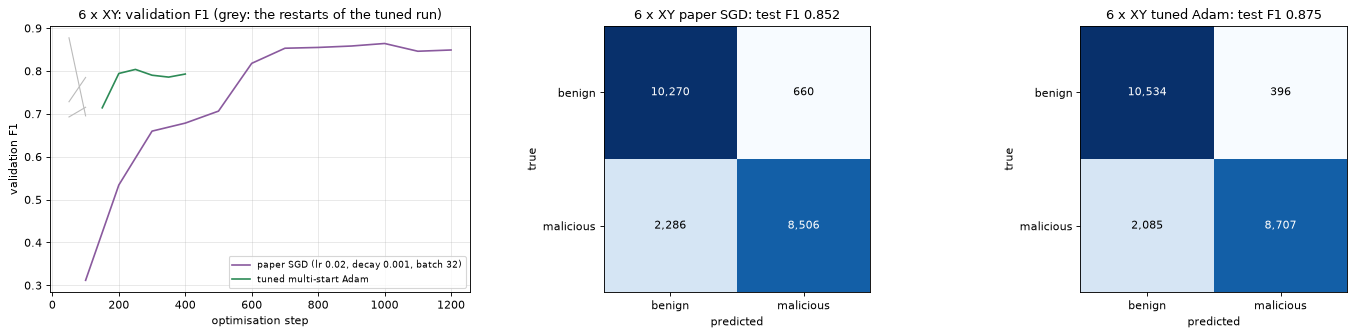

,model,steps,seconds,acc,prec,rec,f1
0,"6L XY, paper SGD",1200,385,0.8644,0.9280,0.7882,0.8524
1,"6L XY, tuned multi-start Adam",600,424,0.8858,0.9565,0.8068,0.8753
2,"2L XY, seed 42",600,128,0.7597,0.6825,0.9656,0.7997


,model,acc,prec,rec,f1,seconds
0,RandomForest(100),0.9883,0.9799,0.9969,0.9883,76.1
1,ExtraTrees(100),0.9871,0.9801,0.9943,0.9871,31.4
2,"SVC(rbf) on 5,000 flows",0.9612,0.9566,0.9657,0.9611,10.4


In [19]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.3))
for nm, key, col in (("paper SGD (lr 0.02, decay 0.001, batch 32)", "6L paper-SGD", "#8a5a9e"), ("tuned multi-start Adam", "6L tuned", "#2e8b57")):
    h = RES[key]["hist"]
    if key == "6L tuned":
        for s_, g in h[h.phase == "select"].groupby("start"): ax[0].plot(g.x, g.val_f1, color="#bbbbbb", lw=1)
        ax[0].plot(h[h.phase == "main"].x, h[h.phase == "main"].val_f1, color=col, label=nm)
    else: ax[0].plot(h.x, h.val_f1, color=col, label=nm)
ax[0].set_xlabel("optimisation step"); ax[0].set_ylabel("validation F1"); ax[0].set_title("6 x XY: validation F1 (grey: the restarts of the tuned run)"); ax[0].legend(fontsize=8)
for k, (key, ttl) in enumerate((("6L paper-SGD", "paper SGD"), ("6L tuned", "tuned Adam"))):
    cm = RES[key]["test"]["cm"]; a = ax[1 + k]
    a.imshow(cm, cmap="Blues"); a.set_xticks([0, 1]); a.set_yticks([0, 1]); a.set_xticklabels(["benign", "malicious"]); a.set_yticklabels(["benign", "malicious"])
    for i in range(2):
        for j in range(2): a.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    a.set_xlabel("predicted"); a.set_ylabel("true"); a.set_title(f"6 x XY {ttl}: test F1 {RES[key]['test']['f1']:.3f}"); a.grid(False)
plt.tight_layout(); plt.show()
TAB_MAIN = pd.DataFrame([dict(model=RES[k]["label"], steps=RES[k]["steps"], seconds=round(RES[k]["seconds"]), **{m: round(RES[k]["test"][m], 4) for m in ("acc", "prec", "rec", "f1")}) for k in ("6L paper-SGD", "6L tuned")] +
                        [dict(model=r["label"], steps=r["steps"], seconds=round(r["seconds"]), **{m: round(r["test"][m], 4) for m in ("acc", "prec", "rec", "f1")}) for r in RES["2L tuned"]])
display(TAB_MAIN)
display(BASE[BASE.inputs == "8 encoded angles"][["model", "acc", "prec", "rec", "f1", "seconds"]])

## 7. Architectures, depth, layer type and optimiser (paper Tables 2, 3, 4)

The paper's hyper-parameter search ran on a GPU-class budget and its tables are images, so only the *claims* in the text can be tested: (i) "Simple" beats the other architectures, (ii) F1 improves with depth and XY is the best layer type, (iii) Adam converges faster while SGD gives the better network. We run these at the reduced budgets of the configuration cell, with the same validation-based selection as above, so a difference of one or two F1 points between two cells of the grids is within the seed-to-seed spread and must not be over-read (the grids use one seed). To keep the notebook affordable these secondary experiments (architectures, grids, optimiser table, encoding ablation, angle precision) are scored on a fixed random subset of `EVAL_N` test flows (`A_EV`); the headline models of section 6 and the noise study use the full test set.

In [20]:
# 7.1 architectures (Table 2): Simple 6xXY vs TTN vs QCNN at the same budget (MERA is not implemented)
ARCH = []
for nm, mdl in (("Simple 6xXY", M6), ("TTN", TTN), ("QCNN", QCNN)):
    r = train_model(mdl, A_FIT, S_FIT, A_VAL, S_VAL, optimizer="adam", seed=SEED, lr0=0.02, lr1=0.002, eval_every=max(GEN["iters"] // 4, 25), label=nm, **GEN)
    ev = evaluate(mdl, r["theta"], A_EV, Y_EV, S_EV)
    ARCH.append(dict(architecture=nm, parameters=mdl.n_params, steps=r["steps"], seconds=round(r["seconds"]), val_f1=round(r["val_f1"], 4), test_f1=round(ev["f1"], 4), test_acc=round(ev["acc"], 4)))
ARCH = pd.DataFrame(ARCH); display(ARCH)

,architecture,parameters,steps,seconds,val_f1,test_f1,test_acc
0,Simple 6xXY,96,220,233,0.8724,0.8642,0.8727
1,TTN,42,220,200,0.8152,0.8124,0.7980
2,QCNN,36,220,507,0.8059,0.8077,0.7830


layers,1,2
layer_type,,
XY,0.6658,0.7969
ZXY,0.8387,0.8059


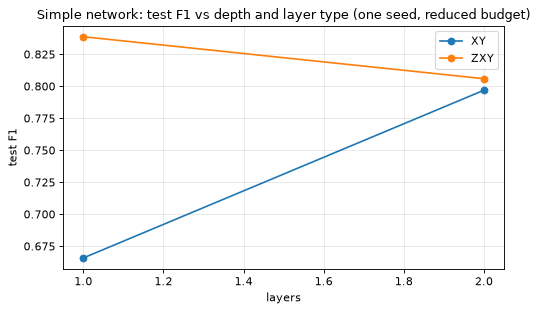

In [21]:
# 7.2 depth x layer type (Table 3)
GRID_RES, GRID_THETA = [], {}
for lt in GRID["types"]:
    for L in GRID["depths"]:
        mdl = SimpleQNN(L, lt)
        r = train_model(mdl, A_FIT, S_FIT, A_VAL, S_VAL, optimizer="adam", seed=SEED, starts=GRID["starts"], sel_iters=GRID["sel_iters"], sel_bs=64, iters=GRID["iters"], bs=GRID["bs"],
                        lr0=0.02, lr1=0.002, eval_every=max(GRID["iters"] // 4, 25), label=mdl.name)
        ev = evaluate(mdl, r["theta"], A_EV, Y_EV, S_EV); GRID_THETA[(L, lt)] = r["theta"]
        GRID_RES.append(dict(layer_type=lt, layers=L, parameters=mdl.n_params, seconds=round(r["seconds"]), val_f1=round(r["val_f1"], 4), test_f1=round(ev["f1"], 4)))
GRID_RES = pd.DataFrame(GRID_RES)
PIV = GRID_RES.pivot(index="layer_type", columns="layers", values="test_f1"); display(PIV)
fig, ax = plt.subplots(1, 1, figsize=(6.5, 4))
for lt in GRID["types"]:
    g = GRID_RES[GRID_RES.layer_type == lt]; ax.plot(g.layers, g.test_f1, "o-", label=lt)
ax.set_xlabel("layers"); ax.set_ylabel("test F1"); ax.set_title("Simple network: test F1 vs depth and layer type (one seed, reduced budget)"); ax.legend(); plt.tight_layout(); plt.show()

In [22]:
# 7.3 optimiser x learning rate (Table 4): 2-layer XY, one random start, same number of steps
OPT = []
for opt in OPT_TABLE["opts"]:
    for lr in OPT_TABLE["lrs"]:
        kw = dict(optimizer="sgd", decay=0.001, max_iters=OPT_TABLE["iters"], bs=OPT_TABLE["bs"], lr0=lr) if opt == "sgd" else dict(optimizer="adam", starts=1, sel_iters=0, iters=OPT_TABLE["iters"], bs=OPT_TABLE["bs"], lr0=lr, lr1=lr)
        r = train_model(SimpleQNN(OPT_TABLE["L"], "XY"), A_FIT, S_FIT, A_VAL, S_VAL, seed=SEED, eval_every=max(OPT_TABLE["iters"] // 10, 10), label=f"{opt} {lr}", **kw)
        h = r["hist"]; conv = int(h[h.val_f1 >= r["val_f1"] - 0.01].step.min())
        ev = evaluate(SimpleQNN(OPT_TABLE["L"], "XY"), r["theta"], A_EV, Y_EV, S_EV)
        OPT.append(dict(optimizer=opt, lr=lr, best_val_f1=round(r["val_f1"], 4), test_f1=round(ev["f1"], 4), steps_to_within_0_01_of_best=conv))
OPT = pd.DataFrame(OPT); display(OPT)

,optimizer,lr,best_val_f1,test_f1,steps_to_within_0_01_of_best
0,sgd,0.10,0.8419,0.8279,120
1,sgd,0.02,0.5760,0.5740,150
2,adam,0.10,0.8607,0.8463,120
3,adam,0.02,0.7980,0.7876,30


## 8. Does the encoding matter? (ablation, 2-layer XY)

The paper's central classical contribution is the encoding of NetFlow features into angles. Because the paper's Table 1 is not readable, the percentile rule had to be interpreted (ties!). Here the same 2-layer network and the same training budget are run on four encodings of the same flows: the one used in this notebook (mid-rank percentile, TCP flags categorical), the same percentile rule with ties placed at the *top* of their percentile range, a log-scaled min-max (not the paper's rule), and the paper's own "naive" linear rule `theta = pi x / max x` that the authors call impractical. Only the first is the paper's rule as we read it; the others show how much of the QNN's score is decided by the classical pre-processing.

In [23]:
class TopTieEncoder(AngleEncoder):
    # same as AngleEncoder but ties get the TOP of their percentile range (np.searchsorted side='right')
    def transform(self, X):
        out = np.zeros(X.shape)
        for j, (kind, a) in enumerate(self.spec):
            x = X[:, j]
            if kind == "cat":
                i = np.clip(np.searchsorted(a, x), 1, len(a) - 1); i = np.where(np.abs(x - a[i - 1]) <= np.abs(a[i] - x), i - 1, i); out[:, j] = np.pi * i / (len(a) - 1)
            else:
                f = np.searchsorted(a, x, side="right") / len(a); out[:, j] = np.pi * np.minimum(np.floor(f * self.n_bins), self.n_bins - 1) / (self.n_bins - 1)
        return out
class NaiveLinearEncoder:
    def fit(self, X): self.mx = X.max(0); return self
    def transform(self, X): return np.clip(X / self.mx, 0, 1) * np.pi
ENC_ABL = {"mid-rank percentile (this notebook)": None, "percentile, ties at top": TopTieEncoder().fit(RAW_TR), "log1p + min-max": LogMinMaxEncoder().fit(RAW_TR), "naive linear pi x / max x": NaiveLinearEncoder().fit(RAW_TR)}
ABL = []
for nm, enc in ENC_ABL.items():
    if enc is None: a_tr, a_te = A_TR, A_TE; r = BEST2; th = r["theta"]; val_f = r["val_f1"]
    else:
        a_tr, a_te = enc.transform(RAW_TR), enc.transform(RAW_TE)
        r = train_model(M2, a_tr[FIT_IDX], S_TR[FIT_IDX], a_tr[VAL_IDX], S_TR[VAL_IDX], optimizer="adam", seed=SEEDS_2L[0], label=nm, **TUNED_2L); th = r["theta"]; val_f = r["val_f1"]
    ev = evaluate(M2, th, a_te[EV_IDX], Y_EV, S_EV)
    rf = RandomForestClassifier(40, random_state=SEED, n_jobs=2).fit(a_tr[:40000], Y_TR[:40000]); f_rf = f1_score(Y_EV, rf.predict(a_te[EV_IDX]))
    ABL.append(dict(encoding=nm, QNN_2L_val_f1=round(val_f, 4), QNN_2L_test_f1=round(ev["f1"], 4), RandomForest40_40kflows_test_f1=round(f_rf, 4)))
ABL = pd.DataFrame(ABL); display(ABL)
# does a better classical encoding let the 6-layer network reach the paper's 0.907?  (log1p + min-max, same tuned budget, full test set)
LM = ENC_ABL["log1p + min-max"]; A_LM_TR, A_LM_TE = LM.transform(RAW_TR), LM.transform(RAW_TE)
RES["6L tuned logminmax"] = train_model(M6, A_LM_TR[FIT_IDX], S_TR[FIT_IDX], A_LM_TR[VAL_IDX], S_TR[VAL_IDX], optimizer="adam", seed=SEED, label="6L XY, tuned, log1p + min-max encoding", **TUNED_6L)
r = RES["6L tuned logminmax"]; r["test"] = evaluate(M6, r["theta"], A_LM_TE, Y_TE, S_TE)
print(f"{r['label']}: start validation F1s {r['start_scores']} | TEST F1 {r['test']['f1']:.4f}, accuracy {r['test']['acc']:.4f}  (paper's encoding, same budget: {RES['6L tuned']['test']['f1']:.4f})")

,encoding,QNN_2L_val_f1,QNN_2L_test_f1,RandomForest40_40kflows_test_f1
0,mid-rank percentile (this notebook),0.7998,0.7989,0.9867
1,"percentile, ties at top",0.7463,0.7418,0.9860
2,log1p + min-max,0.9043,0.8987,0.9872
3,naive linear pi x / max x,0.7484,0.7385,0.9872


6L XY, tuned, log1p + min-max encoding: start validation F1s [0.9012, 0.8844, 0.8814] | TEST F1 0.9001, accuracy 0.8984  (paper's encoding, same budget: 0.8753)


## 9. Noise (paper Sec. III-F and IV-B to IV-D)

**What the authors did.** They trained noiselessly, then ran the inference circuits (a state-preparation circuit followed by the network, one circuit per test flow) on IonQ's noisy simulators of Harmony and Aria-1 and on the real machines, counting shots and taking the majority vote.

**What can be done here, exactly.** IonQ's noise models are proprietary and no IonQ device is available, so noise is modelled by *depolarising channels after every gate* (average gate infidelity `r1` for one-qubit gates, `r2` for two-qubit gates) plus a *symmetric read-out flip* `ro`, with IonQ-class rates that are approximate recollections of public spec sheets and **not** calibrated to the paper (see `NOISE_POINTS`; the conclusions are checked against a sweep of `r2`). Instead of simulating a 512 x 512 density matrix for every one of the thousands of test flows, the noise is propagated once through the circuit in the **Heisenberg picture**: the observable `X_readout` is pulled backwards through the circuit (conjugation by each `Rxx` / `Ryy`, and the adjoint of the depolarising channel) into one *effective noisy observable* `O_eff` that does not depend on the input flow; the noisy expectation of any flow is then `Tr(O_eff rho_in)`, a product-state contraction. A cell asserts that this equals **Qiskit Aer's density-matrix simulation with the same noise model** (asserted to agree to better than 1e-6). Shots are drawn from the exact noisy probability: `n_plus ~ Binomial(SHOTS, (1 + E) / 2)`, majority vote, ties broken by a fair coin. The certainty factor of a flow is `C = y * E` with `y = +-1` the true class (positive = correct side).

In [24]:
def lam_from_error(avg_gate_error, nq):
    d = 2 ** nq; return avg_gate_error * d / (d - 1)       # Aer's depolarizing parameter lambda from the average gate infidelity
def _bit(q): return (_idx >> (NT - 1 - q)) & 1
def conj_gate(O, P, j, th):
    # O -> U^dagger O U for U = exp(-i th/2 P_j (x) P_readout), P in {XX, YY, ZZ}, on the 512 x 512 matrix O
    c, s = np.cos(th / 2), np.sin(th / 2)
    if P == "ZZ": ph = (c + 1j * s * (1 - 2 * (_bit(j) ^ _bit(NQ))))[:, None]; dag = lambda M: ph * M
    else:
        perm = _idx ^ ((1 << (NT - 1 - j)) | 1)
        sgn = np.ones(DIM) if P == "XX" else np.where(_bit(j) == _bit(NQ), -1.0, 1.0)
        dag = lambda M: c * M + 1j * s * (sgn[:, None] * M[perm])
    return dag(dag(O).conj().T).conj().T                      # (U^dag O) U = (U^dag (U^dag O)^dag)^dag
def depol_adjoint(O, lam, j):
    # two-qubit depolarising channel on (feature qubit j, readout): rho -> (1-lam) rho + lam Tr_{jR}(rho) (x) I/4; self-adjoint
    T = O.reshape((2,) * (2 * NT)); rest = [q for q in range(NT) if q not in (j, NQ)]
    order = rest + [NT + q for q in rest] + [j, NT + j, NQ, NT + NQ]
    Pm = T.transpose(order).reshape(2 ** len(rest), 2 ** len(rest), 2, 2, 2, 2); tr = np.einsum("abuuvv->ab", Pm); I2 = np.eye(2) / 2
    R = np.einsum("ab,uw,vx->abuwvx", tr, I2, I2).reshape((2,) * (2 * NT)).transpose(np.argsort(order)).reshape(DIM, DIM)
    return (1 - lam) * O + lam * R
def effective_observable(theta, blocks, lam2, lam1_end=0.0):
    # Heisenberg-picture noisy observable: X_readout (after the one-qubit depolarising error of the final H), pulled back through every gate
    XR = np.zeros((DIM, DIM)); XR[_idx, _idx ^ 1] = 1.0
    O = XR * (1 - lam1_end); th = theta.reshape(len(blocks), NQ)
    for k in range(len(blocks) - 1, -1, -1):
        for j in range(NQ - 1, -1, -1):
            if lam2 > 0: O = depol_adjoint(O, lam2, j)
            O = conj_gate(O, blocks[k] * 2, j, th[k, j])
    return O
PAULIS = np.array([np.eye(2), [[0, 1], [1, 0]], [[0, -1j], [1j, 0]], np.diag([1.0, -1.0])], complex)
def pauli_coeffs(O):
    # c[p0..p8] = Tr(P_p0 (x) ... (x) P_p8 O) / 512, P in I, X, Y, Z
    c = O.reshape((2,) * (2 * NT)); A = PAULIS.transpose(2, 1, 0) / 2.0
    for q in range(NT): c = np.tensordot(c, A, axes=([0, NT - q], [0, 1]))
    return np.real(c)
def bloch_inputs(X, lam1):
    # (1, <X>, <Y>, <Z>) of every input qubit: Rx(x)|0> shrunk by the one-qubit depolarising error of the Rx, readout |-> shrunk by the errors of X and H
    v = np.zeros((X.shape[0], NT, 4)); v[:, :, 0] = 1.0
    v[:, :NQ, 2] = -np.sin(X) * (1 - lam1); v[:, :NQ, 3] = np.cos(X) * (1 - lam1); v[:, NQ, 1] = -(1 - lam1) ** 2
    return v
def expectation_batch(c, V, bs=128):
    out = []
    for i in range(0, len(V), bs):
        v = V[i:i + bs]; A = v[:, 0, :] @ c.reshape(4, -1)
        for q in range(1, NT): A = np.einsum("bp,bpr->br", v[:, q, :], A.reshape(len(v), 4, -1))
        out.append(A[:, 0])
    return np.concatenate(out)
class NoisyQNN:
    # exact noisy expectation <X_readout> of a trained Simple network for IonQ-like depolarising + read-out noise
    def __init__(self, theta, blocks, r1, r2, ro):
        self.lam1, self.lam2, self.ro = lam_from_error(r1, 1), lam_from_error(r2, 2), ro
        t0 = time.perf_counter(); self.c = pauli_coeffs(effective_observable(theta, blocks, self.lam2, self.lam1)); self.seconds = time.perf_counter() - t0
    def E(self, X, with_readout=True):
        return expectation_batch(self.c, bloch_inputs(X, self.lam1)) * ((1 - 2 * self.ro) if with_readout else 1.0)
def shot_predictions(E, shots, rng):
    n_plus = rng.binomial(shots, np.clip((1 + E) / 2, 0, 1)); pred = (n_plus > shots / 2).astype(int)
    tie = n_plus * 2 == shots; pred[tie] = rng.integers(0, 2, tie.sum()); return pred

In [25]:
# equivalence 1: with zero noise the Heisenberg-picture machinery reproduces the ideal simulator;
# equivalence 2: with noise it reproduces Qiskit Aer's density-matrix simulation (same depolarising channels) to ~1e-8
rng_t = np.random.default_rng(5); Xs = rng_t.uniform(0, np.pi, (3, NQ)); th_t = THETA_2L
ideal = M2.predict(Xs, th_t); zero = NoisyQNN(th_t, M2.blocks, 0, 0, 0).E(Xs)
print("ideal vs Heisenberg(noise=0): max diff %.1e" % np.abs(ideal - zero).max()); assert np.abs(ideal - zero).max() < 1e-5
chk = dict(r1=2e-3, r2=2e-2); nq_ = NoisyQNN(th_t, M2.blocks, chk["r1"], chk["r2"], 0.0); Eh = nq_.E(Xs, with_readout=False)
nm = NoiseModel(); nm.add_all_qubit_quantum_error(depolarizing_error(lam_from_error(chk["r1"], 1), 1), ["rx", "h", "x"])
nm.add_all_qubit_quantum_error(depolarizing_error(lam_from_error(chk["r2"], 2), 2), ["rxx", "ryy"])
sim_dm = AerSimulator(method="density_matrix", noise_model=nm); qc2, xp2, tp2 = simple_qiskit(2, "XY"); Ea = []
for i in range(len(Xs)):
    qq = bind(qc2, xp2, tp2, Xs[i], th_t); qq.save_probabilities([NQ], label="p")
    p = sim_dm.run(transpile(qq, sim_dm, optimization_level=0)).result().data()["p"]; Ea.append(p[0] - p[1])
print("Heisenberg-picture noisy <X>:", np.round(Eh, 8), "\nQiskit Aer density matrix  :", np.round(Ea, 8), "\nmax difference %.1e (ideal values %s)" % (np.abs(Eh - np.array(Ea)).max(), np.round(ideal, 4)))
assert np.abs(Eh - np.array(Ea)).max() < 1e-6

ideal vs Heisenberg(noise=0): max diff 7.4e-08


Heisenberg-picture noisy <X>: [-0.03641849  0.14277972  0.08463689] 
Qiskit Aer density matrix  : [-0.03641849  0.14277972  0.08463689] 
max difference 4.0e-16 (ideal values [-0.0498  0.2939  0.2773])


In [26]:
# noisy inference on the full test set, 6-layer network, at the two IonQ-like noise points
rngN = np.random.default_rng(SEED)
NOISY6 = {}
E0 = M6.predict(A_TE, THETA_6L)
NOISY6["noiseless"] = E0
rows = []
def noise_rows(label, E, exact_label):
    rows.append(dict(setting=exact_label, shots="inf", f1=round(f1_score(Y_TE, E > 0), 4), acc=round(accuracy_score(Y_TE, E > 0), 4), mean_certainty=round(float(np.mean(S_TE * E)), 4)))
    for sh in SHOTS_SENS:
        pshot = shot_predictions(E, sh, rngN)
        rows.append(dict(setting=f"{label}, majority of shots", shots=sh, f1=round(f1_score(Y_TE, pshot), 4), acc=round(accuracy_score(Y_TE, pshot), 4), mean_certainty=round(float(np.mean(S_TE * E)), 4)))
noise_rows("noiseless", E0, "noiseless (exact sign)")
for nm_, pr in NOISE_POINTS.items():
    q = NoisyQNN(THETA_6L, M6.blocks, **pr); E = q.E(A_TE); NOISY6[nm_] = E
    noise_rows(nm_, E, f"{nm_} (r1={pr['r1']}, r2={pr['r2']}, ro={pr['ro']}), exact sign")
    print(f"{nm_}: observable built in {q.seconds:.0f} s")
TAB_NOISE6 = pd.DataFrame(rows); display(TAB_NOISE6)

Aria-like: observable built in 96 s


Intermediate: observable built in 69 s


Harmony-like: observable built in 55 s


,setting,shots,f1,acc,mean_certainty
0,noiseless (exact sign),inf,0.8753,0.8858,0.2787
1,"noiseless, majority of shots",200,0.8170,0.8350,0.2787
2,"noiseless, majority of shots",1000,0.8458,0.8603,0.2787
3,"noiseless, majority of shots",10000,0.8727,0.8833,0.2787
4,"Aria-like (r1=0.0005, r2=0.005, ro=0.004), exa...",inf,0.8757,0.8860,0.1563
5,"Aria-like, majority of shots",200,0.7845,0.8024,0.1563
6,"Aria-like, majority of shots",1000,0.8249,0.8421,0.1563
7,"Aria-like, majority of shots",10000,0.8630,0.8745,0.1563
8,"Intermediate (r1=0.001, r2=0.01, ro=0.004), ex...",inf,0.8765,0.8864,0.0882
9,"Intermediate, majority of shots",200,0.7541,0.7685,0.0882


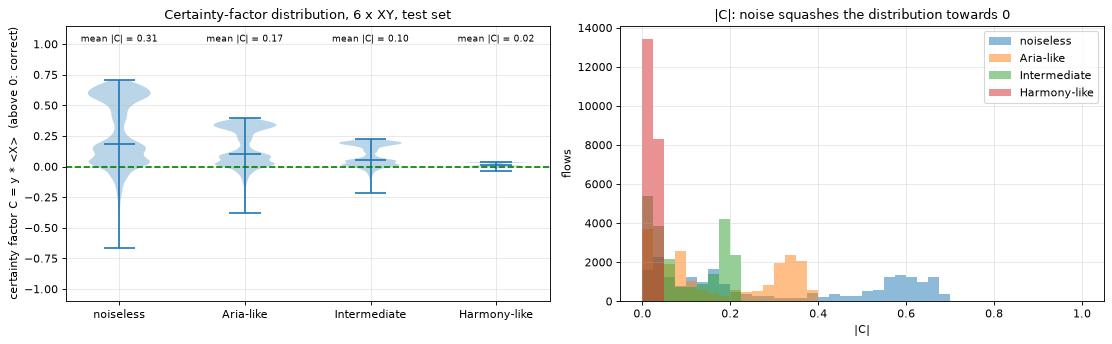

In [27]:
# Fig. 7 analogue: violin plots of the certainty factor C = y * E on the test set, 6-layer network
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
labels = ["noiseless"] + list(NOISE_POINTS); data = [S_TE * NOISY6[k] for k in labels]
vp = ax[0].violinplot(data, showmedians=True); ax[0].set_xticks(range(1, len(labels) + 1)); ax[0].set_xticklabels(labels); ax[0].axhline(0, color="green", ls="--")
ax[0].set_ylabel("certainty factor C = y * <X>  (above 0: correct)"); ax[0].set_title("Certainty-factor distribution, 6 x XY, test set")
for k, d in enumerate(data): ax[0].text(k + 1, 1.02, f"mean |C| = {np.mean(np.abs(d)):.2f}", ha="center", fontsize=8)
ax[0].set_ylim(-1.1, 1.15)
for k, lab in enumerate(labels): ax[1].hist(np.abs(NOISY6[lab]), bins=40, range=(0, 1), alpha=0.5, label=lab)
ax[1].set_xlabel("|C|"); ax[1].set_ylabel("flows"); ax[1].set_title("|C|: noise squashes the distribution towards 0"); ax[1].legend()
plt.tight_layout(); plt.show()

### 9.1 Sweeping the two-qubit error rate

The labelled noise points above are guesses at IonQ-class rates; the sweep shows how the F1 of the exact-sign classifier and of the `SHOTS_SIM`-shot majority vote depends on the two-qubit error `r2` (with `r1 = r2 / 10` and `ro = 0.004`) for the 2-layer network (each point needs a Heisenberg sweep through the circuit; the 6-layer network is shown at the labelled noise points above). Mean |C| measures how far noise has squashed the output; with `n` shots a flow is classified reliably only if |C| is clearly above about `1/sqrt(n)`.

,network,r2,f1_exact_sign,f1_shots,mean_abs_C,shots
0,2 x XY,0.000,0.7997,0.7985,0.5163,1000
1,2 x XY,0.002,0.7994,0.7981,0.4765,1000
2,2 x XY,0.005,0.7995,0.7991,0.4275,1000
3,2 x XY,0.010,0.7988,0.7987,0.3566,1000
4,2 x XY,0.025,0.7977,0.7974,0.2065,1000
5,6 x XY,0.005,0.8757,0.8243,0.1734,1000
6,6 x XY,0.010,0.8765,0.7984,0.0978,1000
7,6 x XY,0.025,0.8605,0.6587,0.0173,1000


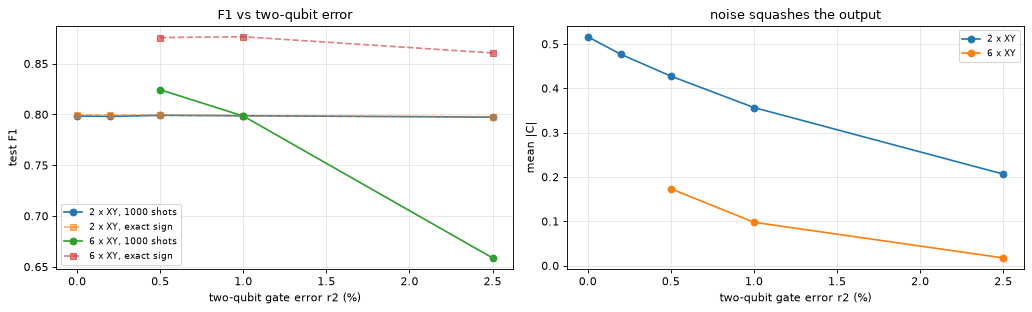

In [28]:
SWEEP = []
rngS = np.random.default_rng(SEED + 1)
for r2 in SWEEP_R2:
    qn = NoisyQNN(THETA_2L, M2.blocks, r2 / 10, r2, 0.004 if r2 > 0 else 0.0); E = qn.E(A_TE)
    SWEEP.append(dict(network="2 x XY", r2=r2, f1_exact_sign=f1_score(Y_TE, E > 0), f1_shots=f1_score(Y_TE, shot_predictions(E, SHOTS_SIM, rngS)), mean_abs_C=float(np.mean(np.abs(E)))))
for nm_, pr in NOISE_POINTS.items():          # the 6-layer network at the two labelled noise points (already computed above)
    E = NOISY6[nm_]; SWEEP.append(dict(network="6 x XY", r2=pr["r2"], f1_exact_sign=f1_score(Y_TE, E > 0), f1_shots=f1_score(Y_TE, shot_predictions(E, SHOTS_SIM, rngS)), mean_abs_C=float(np.mean(np.abs(E)))))
SWEEP = pd.DataFrame(SWEEP); SWEEP["shots"] = SHOTS_SIM; display(SWEEP.round(4))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for tag, g in SWEEP.groupby("network"):
    ax[0].plot(g.r2 * 100, g.f1_shots, "o-", label=f"{tag}, {SHOTS_SIM} shots"); ax[0].plot(g.r2 * 100, g.f1_exact_sign, "s--", alpha=0.6, label=f"{tag}, exact sign")
    ax[1].plot(g.r2 * 100, g.mean_abs_C, "o-", label=tag)
ax[0].set_xlabel("two-qubit gate error r2 (%)"); ax[0].set_ylabel("test F1"); ax[0].set_title("F1 vs two-qubit error"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("two-qubit gate error r2 (%)"); ax[1].set_ylabel("mean |C|"); ax[1].set_title("noise squashes the output"); ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

### 9.2 The Aria-1 experiment, simulated: 2-layer network on a balanced 776-flow subset (Tables 6 and 7, Fig. 8)

The authors drew a balanced random subset of 776 test flows (3.5 % of the test set) for the Aria-1 QPU. The same subset size is drawn here (388 benign + 388 malicious, seeded), the 2-layer network is evaluated noiselessly on the full test set and on the subset, and with Aria-like noise on the subset (200 shots per flow). The real-hardware column of the paper's Table 6 (F1 0.86) **cannot be reproduced without the machine**; the noisy simulation is its stand-in, exactly as in the paper (which also compared noisy simulation with hardware).

,scenario,n,f1
0,"noiseless, full test set",21722,0.7997
1,"noiseless, 776 subset",776,0.8077
2,"Aria-like noisy simulation, 776 subset, 200 shots",776,0.8030
3,real Aria-1 hardware (paper: 0.86),776,NaN


confusion matrix [rows true benign / malicious, columns predicted], Aria-like noisy simulation on the subset:
 [[217 171]
 [ 13 375]]
confusion matrix, noiseless on the subset:
 [[218 170]
 [ 10 378]]


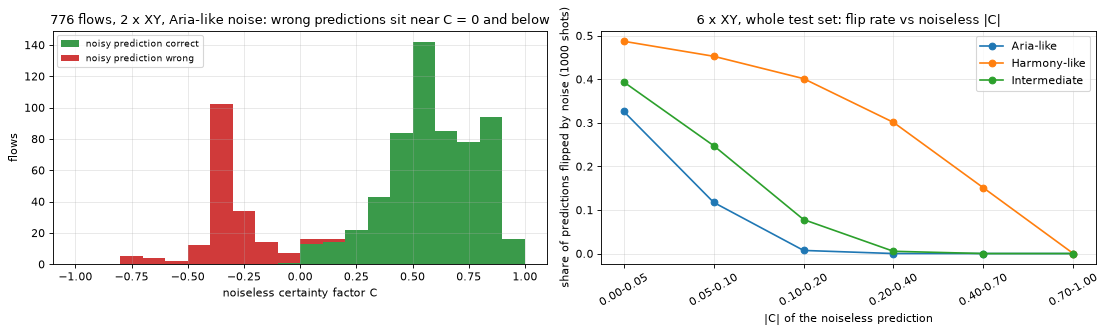

noise,Aria-like,Harmony-like,Intermediate
abs_C_noiseless,,,
0.00-0.05,0.326,0.487,0.394
0.05-0.10,0.117,0.453,0.248
0.10-0.20,0.007,0.401,0.078
0.20-0.40,0.000,0.301,0.005
0.40-0.70,0.000,0.151,0.000
0.70-1.00,0.000,0.000,0.000


In [29]:
rngH = np.random.default_rng(SEED + 2)
half = SUBSET_N // 2
SUB_IDX = np.concatenate([rngH.choice(np.where(Y_TE == 0)[0], half, replace=False), rngH.choice(np.where(Y_TE == 1)[0], half, replace=False)])
E2_full = M2.predict(A_TE, THETA_2L); E2_sub = E2_full[SUB_IDX]
q2 = NoisyQNN(THETA_2L, M2.blocks, **NOISE_POINTS["Aria-like"]); E2_noisy_sub = q2.E(A_TE[SUB_IDX]); pred_noisy_sub = shot_predictions(E2_noisy_sub, SHOTS_HW, rngH)
T6 = pd.DataFrame([
    dict(scenario="noiseless, full test set", n=len(Y_TE), f1=round(f1_score(Y_TE, E2_full > 0), 4)),
    dict(scenario="noiseless, 776 subset", n=SUBSET_N, f1=round(f1_score(Y_TE[SUB_IDX], E2_sub > 0), 4)),
    dict(scenario=f"Aria-like noisy simulation, 776 subset, {SHOTS_HW} shots", n=SUBSET_N, f1=round(f1_score(Y_TE[SUB_IDX], pred_noisy_sub), 4)),
    dict(scenario="real Aria-1 hardware (paper: 0.86)", n=SUBSET_N, f1=np.nan)]); display(T6)
print("confusion matrix [rows true benign / malicious, columns predicted], Aria-like noisy simulation on the subset:\n", confusion_matrix(Y_TE[SUB_IDX], pred_noisy_sub, labels=[0, 1]))
print("confusion matrix, noiseless on the subset:\n", confusion_matrix(Y_TE[SUB_IDX], (E2_sub > 0).astype(int), labels=[0, 1]))
# Fig. 8 analogue
C0 = S_TE[SUB_IDX] * E2_sub; correct = pred_noisy_sub == Y_TE[SUB_IDX]
bins = np.linspace(-1, 1, 21); fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].hist([C0[correct], C0[~correct]], bins=bins, stacked=True, color=["#3a9a4a", "#d03a3a"], label=["noisy prediction correct", "noisy prediction wrong"])
ax[0].set_xlabel("noiseless certainty factor C"); ax[0].set_ylabel("flows"); ax[0].set_title("776 flows, 2 x XY, Aria-like noise: wrong predictions sit near C = 0 and below"); ax[0].legend(fontsize=8)
# flips relative to the NOISELESS prediction, over the whole test set (6-layer network, both noise points)
edges = [0, 0.05, 0.1, 0.2, 0.4, 0.7, 1.0001]; fl = []
for nm_ in NOISE_POINTS:
    pr_n = shot_predictions(NOISY6[nm_], SHOTS_SIM, rngH); pr_0 = (NOISY6["noiseless"] > 0).astype(int); ab = np.abs(NOISY6["noiseless"])
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (ab >= lo) & (ab < hi); fl.append(dict(noise=nm_, abs_C_noiseless=f"{lo:.2f}-{min(hi, 1):.2f}", flows=int(m.sum()), flip_rate=float((pr_n[m] != pr_0[m]).mean()) if m.any() else np.nan))
FLIP = pd.DataFrame(fl)
for nm_, g in FLIP.groupby("noise"): ax[1].plot(range(len(g)), g.flip_rate, "o-", label=nm_)
ax[1].set_xticks(range(len(edges) - 1)); ax[1].set_xticklabels(FLIP.abs_C_noiseless.iloc[:len(edges) - 1], rotation=30); ax[1].set_xlabel("|C| of the noiseless prediction"); ax[1].set_ylabel(f"share of predictions flipped by noise ({SHOTS_SIM} shots)")
ax[1].set_title("6 x XY, whole test set: flip rate vs noiseless |C|"); ax[1].legend(); plt.tight_layout(); plt.show(); display(FLIP.pivot(index="abs_C_noiseless", columns="noise", values="flip_rate").round(3))

### 9.3 Rotation-angle precision (paper Fig. 9)

The authors rounded the gate angles to a given number of decimals to test whether the hardware's limited angle precision could explain the Harmony results. Here both the encoding angles and the trained angles are rounded (radians) and the noiseless F1 is recomputed on the full test set for the trained networks of this notebook.

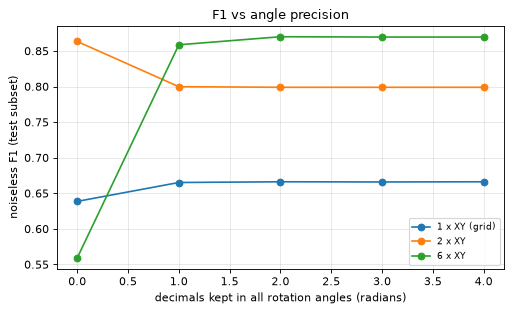

decimals,0,1,2,3,4
network,,,,,
1 x XY (grid),0.6386,0.6651,0.6661,0.6658,0.6661
2 x XY,0.8633,0.7997,0.7989,0.7989,0.7989
6 x XY,0.5591,0.8586,0.8699,0.8695,0.8695


In [30]:
DEC = [0, 1, 2, 3, 4]; PREC = []
models_prec = {"6 x XY": (M6, THETA_6L), "2 x XY": (M2, THETA_2L)}
for (L, lt), th_ in GRID_THETA.items():
    if lt == "XY" and L not in (2, 6): models_prec[f"{L} x XY (grid)"] = (SimpleQNN(L, lt), th_)
for nm_, (mdl, th_) in models_prec.items():
    for d in DEC: PREC.append(dict(network=nm_, decimals=d, f1=f1_score(Y_EV, mdl.predict(np.round(A_EV, d), np.round(th_, d)) > 0)))
PREC = pd.DataFrame(PREC); fig, ax = plt.subplots(1, 1, figsize=(6.5, 4))
for nm_, g in PREC.groupby("network"): ax.plot(g.decimals, g.f1, "o-", label=nm_)
ax.set_xlabel("decimals kept in all rotation angles (radians)"); ax.set_ylabel("noiseless F1 (test subset)"); ax.set_title("F1 vs angle precision"); ax.legend(fontsize=8); plt.tight_layout(); plt.show(); display(PREC.pivot(index="network", columns="decimals", values="f1").round(4))

### 9.4 The same 2-layer circuit on a superconducting device model (`FakeSherbrooke`)

IonQ's all-to-all connectivity is the reason the star-shaped "Simple" circuit is cheap on the paper's hardware. On a heavy-hex IBM chip a gate between the readout qubit and a far feature qubit needs SWAPs. The cell selects a connected 9-qubit patch of the 127-qubit `FakeSherbrooke` (lowest summed error), transpiles the 2-layer circuit with Qiskit (native gates `rz, sx, x, ecr`, routing restricted to the patch), and runs a handful of test flows through Qiskit Aer's density-matrix simulator with the **full backend noise model** (gate errors, relaxation, read-out), 200 shots each. Every run needs several seconds, so only `IBM_N` flows are used; the point is the circuit cost and the shrinkage of the output, not an F1 estimate.

In [31]:
from qiskit_ibm_runtime.fake_provider import FakeSherbrooke
be = FakeSherbrooke(); tgt = be.target
adj = {}
for a_, b_ in be.coupling_map.get_edges(): adj.setdefault(a_, set()).add(b_); adj.setdefault(b_, set()).add(a_)
def _err(a_, b_):
    for k in ((a_, b_), (b_, a_)):
        if k in tgt["ecr"] and tgt["ecr"][k] is not None: return tgt["ecr"][k].error
    return 1.0
best_patch = None
for s0 in adj:                                     # greedy connected patch of 9 qubits, lowest summed CNOT + read-out error  # CHOICE
    S = [s0]
    while len(S) < NT:
        cand = sorted((_err(a_, b_) + tgt["measure"][(b_,)].error, b_) for a_ in S for b_ in adj[a_] if b_ not in S); S.append(cand[0][1])
    sc = sum(tgt["measure"][(q,)].error for q in S) + sum(_err(a_, b_) for a_ in S for b_ in adj[a_] if b_ in S and a_ < b_)
    if best_patch is None or sc < best_patch[0]: best_patch = (sc, S)
PATCH = best_patch[1]; pe = [(a_, b_) for a_ in PATCH for b_ in adj[a_] if b_ in PATCH]; deg = {q: sum(1 for b_ in adj[q] if b_ in PATCH) for q in PATCH}
RO_PHYS = max(PATCH, key=lambda q: deg[q]); LAYOUT = [q for q in PATCH if q != RO_PHYS] + [RO_PHYS]
print("physical patch:", PATCH, "| readout qubit placed on physical qubit", RO_PHYS, "(degree %d)" % deg[RO_PHYS])
qcI, xpI, tpI = simple_qiskit(2, "XY"); qcI.add_register(ClassicalRegister(1, "ro")); qcI.measure(NQ, 0)
tcI = transpile(qcI, coupling_map=CouplingMap(pe), basis_gates=["rz", "sx", "x", "ecr"], initial_layout=LAYOUT, seed_transpiler=SEED, optimization_level=1)
ops_t = dict(tcI.count_ops()); print(f"transpiled for FakeSherbrooke: depth {tcI.depth()} | ecr (two-qubit) gates {ops_t.get('ecr', 0)} | all gates {ops_t} (logical circuit: 32 two-qubit gates)")
sim_ibm = AerSimulator(method="density_matrix", noise_model=NoiseModel.from_backend(be)); rowsI = []
for i in SUB_IDX[:: max(1, len(SUB_IDX) // IBM_N)][:IBM_N]:
    cI = tcI.assign_parameters({**dict(zip(xpI, A_TE[i])), **dict(zip(tpI, THETA_2L))})
    t0 = time.perf_counter(); cnt = sim_ibm.run(cI, shots=SHOTS_HW, seed_simulator=SEED).result().get_counts(); n0 = cnt.get("0", 0)
    rowsI.append(dict(flow=int(i), true_class=int(Y_TE[i]), noiseless_E=round(float(E2_full[i]), 3), FakeSherbrooke_E=round(2 * n0 / SHOTS_HW - 1, 3), seconds=round(time.perf_counter() - t0, 1)))
IBMT = pd.DataFrame(rowsI); display(IBMT)
slope = float(np.sum(IBMT.noiseless_E * IBMT.FakeSherbrooke_E) / np.sum(IBMT.noiseless_E ** 2)); print(f"least-squares shrinkage of <X> on FakeSherbrooke versus the ideal value: {slope:.2f} (1 = no noise); Aria-like depolarising model for the same network: {float(np.sum(E2_full[SUB_IDX] * E2_noisy_sub) / np.sum(E2_full[SUB_IDX] ** 2)):.2f}")

physical patch: [121, 122, 123, 124, 125, 120, 119, 118, 110] | readout qubit placed on physical qubit 121 (degree 2)


transpiled for FakeSherbrooke: depth 562 | ecr (two-qubit) gates 202 | all gates {'rz': 413, 'sx': 266, 'ecr': 202, 'x': 70, 'barrier': 5, 'measure': 1} (logical circuit: 32 two-qubit gates)


,flow,true_class,noiseless_E,FakeSherbrooke_E,seconds
0,13341,0,0.277,0.20,12.9
1,21393,0,-0.668,-0.19,12.3
2,10436,1,0.506,0.19,11.9


least-squares shrinkage of <X> on FakeSherbrooke versus the ideal value: 0.36 (1 = no noise); Aria-like depolarising model for the same network: 0.83


1-layer circuit compiled for FakeSherbrooke: {'rz': 209, 'sx': 130, 'ecr': 89, 'x': 35, 'barrier': 3, 'measure': 1} | depth 276


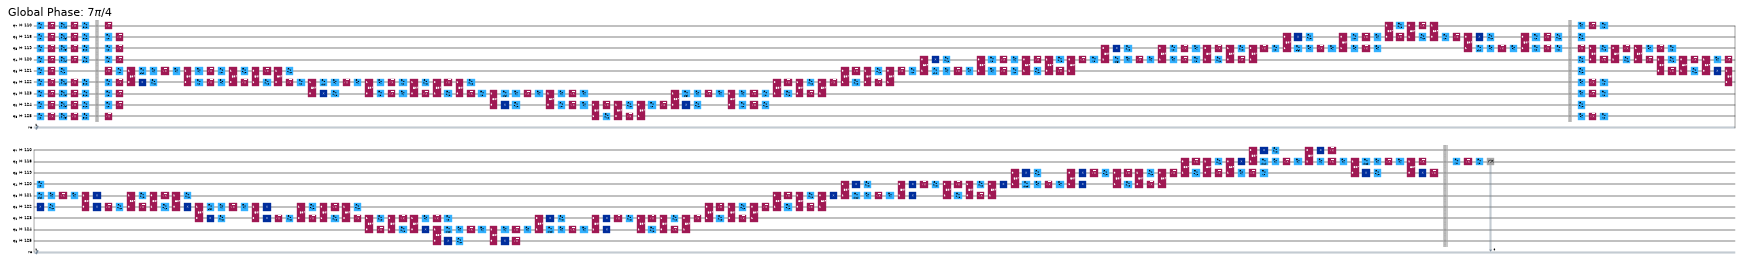

In [32]:
# transpiled 1-layer version for the drawing (the 2-layer circuit has hundreds of gates)
qc1, xp1, tp1 = simple_qiskit(1, "XY"); qc1.add_register(ClassicalRegister(1, "ro")); qc1.measure(NQ, 0)
tc1 = transpile(qc1, coupling_map=CouplingMap(pe), basis_gates=["rz", "sx", "x", "ecr"], initial_layout=LAYOUT, seed_transpiler=SEED, optimization_level=1)
print("1-layer circuit compiled for FakeSherbrooke:", dict(tc1.count_ops()), "| depth", tc1.depth())
display(tc1.draw("mpl", fold=150, scale=0.22, idle_wires=False)); plt.close("all")

### 9.5 Optional: real IBM hardware (skipped without `IBM_TOKEN`)

The paper used IonQ machines through Amazon Braket; those are not reachable from this notebook. If you set `IBM_TOKEN` (a free-tier IBM Quantum API key) in the configuration cell, the cell below sends a few flows through the 2-layer circuit to the least busy IBM device (transpiled with Qiskit, 200 shots). It is **untested here** (no token on the machine that produced the stored outputs).

In [33]:
if IBM_TOKEN:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
    from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
    svc = QiskitRuntimeService(token=IBM_TOKEN); dev = svc.least_busy(operational=True, simulator=False, min_num_qubits=NT)
    pm = generate_preset_pass_manager(backend=dev, optimization_level=1, seed_transpiler=SEED)
    isa = pm.run(qcI); idxs = SUB_IDX[:: max(1, len(SUB_IDX) // 20)][:20]
    pubs = [isa.assign_parameters({**dict(zip(xpI, A_TE[i])), **dict(zip(tpI, THETA_2L))}) for i in idxs]
    job = SamplerV2(mode=dev).run(pubs, shots=SHOTS_HW); res = job.result()
    Ehw = np.array([2 * r.data.ro.get_counts().get("0", 0) / SHOTS_HW - 1 for r in res])
    print(dev.name, "| F1 on", len(idxs), "flows:", f1_score(Y_TE[idxs], Ehw > 0), "| agreement with noiseless prediction:", np.mean((Ehw > 0) == (E2_full[idxs] > 0)))
else:
    print("IBM_TOKEN is empty: real-hardware cell skipped (the paper's own hardware, IonQ Harmony / Aria-1 via Amazon Braket, is not reachable from here).")

IBM_TOKEN is empty: real-hardware cell skipped (the paper's own hardware, IonQ Harmony / Aria-1 via Amazon Braket, is not reachable from here).


## 10. Side-by-side comparison with the paper

Rule (project brief): a numeric claim is **reproduced** when the notebook's value is within 0.02 F1 of the paper's, **exceeded** / **not reached** otherwise (with the gap), and **cannot be checked** when it needs hardware or an image-only table. Qualitative claims get a verdict from the stated test. All notebook numbers are from the configuration printed at the top (see `FAST_MODE`); the grids use one seed and a reduced budget, so the qualitative verdicts about depth, layer type and optimisers are weaker evidence than the headline F1.

In [34]:
def vnum(paper, nb, tol=TOL_F1):
    d = nb - paper
    return "reproduced" if abs(d) <= tol else (f"exceeded (+{d:.3f})" if d > 0 else f"not reached ({d:.3f})")
def fmt(x): return f"{x:.4f}" if isinstance(x, (float, np.floating)) else str(x)
rows = []
def add(claim, paper, nb, verdict, note=""): rows.append(dict(claim=claim, paper=paper, notebook=nb, verdict=verdict, note=note))

f1_sgd = RES["6L paper-SGD"]["test"]["f1"]; f1_tuned = RES["6L tuned"]["test"]["f1"]
add("Data: flows / malicious / balanced samples / test share", "1,623,118 / 72,406 / 144,812 / 15 %", f"{FULL_N:,} / {FULL_ATTACKS:,} / {len(BAL):,} / {len(TE) / len(BAL):.1%}", "reproduced", "same file; the 776-flow subset is 3.6 % of our test set (paper: 3.5 %)")
add("Table 2: best noiseless F1, Simple 6 x XY", 0.907, round(f1_tuned, 4), vnum(0.907, f1_tuned), f"full test set; tuned multi-start Adam, {RES['6L tuned']['steps']:,} steps, pool {len(FIT_IDX):,} flows")
f1_lm = RES["6L tuned logminmax"]["test"]["f1"]
add("Table 2 target with a different encoding (log1p + min-max, NOT the paper's rule), same budget", 0.907, round(f1_lm, 4), vnum(0.907, f1_lm), "ablation of section 8; shows that the classical pre-processing, not the circuit, limits the score of the paper-faithful encoding here")
add("Same, with the paper's hyper-parameters (SGD lr 0.02, decay 0.001, batch 32)", 0.907, round(f1_sgd, 4), vnum(0.907, f1_sgd), f"{RES['6L paper-SGD']['steps']:,} steps only (epochs not stated by the paper)")
A_ = ARCH.set_index("architecture").test_f1
add("Table 2: Simple outperforms the other architectures (TTN, QCNN; MERA not run)", "Simple best", f"Simple {A_['Simple 6xXY']:.3f} / TTN {A_['TTN']:.3f} / QCNN {A_['QCNN']:.3f}", ("reproduced" if A_["Simple 6xXY"] - max(A_["TTN"], A_["QCNN"]) > 0.01 else ("tied (within 0.01)" if A_["Simple 6xXY"] - max(A_["TTN"], A_["QCNN"]) >= -0.01 else "not reached")), f"equal reduced budget, scored on the {EVAL_N:,}-flow test subset; our TTN / QCNN wiring is a reconstruction")
gx = GRID_RES[GRID_RES.layer_type == "XY"].sort_values("layers"); dmax = gx.layers.max()
add("Table 3: F1 improves with depth (XY)", "monotone increase", " / ".join(f"{int(l)}L {f:.3f}" for l, f in zip(gx.layers, gx.test_f1)), "reproduced" if gx.test_f1.iloc[-1] > gx.test_f1.iloc[0] + 0.005 else "not reached", f"one seed, reduced budget, {EVAL_N:,}-flow test subset")
at_max = GRID_RES[GRID_RES.layers == dmax].set_index("layer_type").test_f1
add(f"Table 3: XY is the best layer type (compared at {dmax} layers)", "XY best", " / ".join(f"{k} {v:.3f}" for k, v in at_max.items()), "reproduced" if at_max.idxmax() == "XY" else "not reached", f"one seed, reduced budget, {EVAL_N:,}-flow test subset")
o_ = OPT.groupby("optimizer").agg(steps=("steps_to_within_0_01_of_best", "median"), best=("test_f1", "max"))
add("Table 4: Adam converges faster than SGD", "Adam faster", f"median steps to within 0.01 of best val F1: Adam {o_.loc['adam', 'steps']:.0f}, SGD {o_.loc['sgd', 'steps']:.0f}", "reproduced" if o_.loc["adam", "steps"] < o_.loc["sgd", "steps"] else "not reached", "2 x XY, one random start, fixed lr per run")
add("Table 4: SGD gives the better network", "SGD better", f"best test F1: SGD {o_.loc['sgd', 'best']:.3f}, Adam {o_.loc['adam', 'best']:.3f}", "reproduced" if o_.loc["sgd", "best"] > o_.loc["adam", "best"] else "not reached", "short budget: SGD with lr decay vs Adam with constant lr")
sel_ = TAB_NOISE6.shots.astype(str) == str(SHOTS_SIM)
f_ar = TAB_NOISE6[sel_ & TAB_NOISE6.setting.str.startswith("Aria-like")].f1.iloc[0]
f_ha = TAB_NOISE6[sel_ & TAB_NOISE6.setting.str.startswith("Harmony-like")].f1.iloc[0]
f_ar_all = TAB_NOISE6[TAB_NOISE6.setting.str.startswith("Aria-like")].set_index("shots").f1.to_dict(); f_ha_all = TAB_NOISE6[TAB_NOISE6.setting.str.startswith("Harmony-like")].set_index("shots").f1.to_dict()
add("Sec. IV-B: noisy simulation F1, 6 x XY, Aria-1 model", 0.886, round(f_ar, 4), vnum(0.886, f_ar), f"{SHOTS_SIM} shots; F1 by shots {f_ar_all}; our Aria-like depolarising model is approximate (not IonQ's)")
add("Sec. IV-B: noisy simulation F1, 6 x XY, Harmony model", 0.8789, round(f_ha, 4), vnum(0.8789, f_ha), f"{SHOTS_SIM} shots; F1 by shots {f_ha_all}; our Harmony-like model is approximate (not IonQ's)")
f_nl = TAB_NOISE6[sel_ & TAB_NOISE6.setting.str.startswith("noiseless, majority")].f1.iloc[0]
f_mid = TAB_NOISE6[sel_ & TAB_NOISE6.setting.str.startswith("Intermediate")].f1.iloc[0]
add("Sec. IV-B: F1 lost to noise, 6 x XY, Aria-1 model (noisy minus noiseless, same shots)", round(0.886 - 0.907, 3), round(f_ar - f_nl, 4), vnum(0.886 - 0.907, f_ar - f_nl), f"noiseless majority-of-{SHOTS_SIM}-shots F1 {f_nl:.3f}; the paper's loss is 0.907 -> 0.886")
add("Sec. IV-B: F1 lost to noise, 6 x XY, Harmony model (noisy minus noiseless, same shots)", round(0.8789 - 0.907, 3), round(f_ha - f_nl, 4), vnum(0.8789 - 0.907, f_ha - f_nl), f"our intermediate point (r2 = 1 %) loses {f_mid - f_nl:+.3f}; the paper's 0.8789 is compatible with an effective two-qubit error between the Aria-like and Harmony-like points")
f_full, f_sub = T6.f1.iloc[0], T6.f1.iloc[1]
add("Table 6: noiseless F1 on the 776 subset is close to the full test set", "nearly identical", f"full {f_full:.3f} / subset {f_sub:.3f}", "reproduced" if abs(f_full - f_sub) <= TOL_F1 else "not reached", "2 x XY")
add("Table 6: Aria-1 hardware F1 (2 x XY, 776 flows)", 0.86, f"noisy simulation stand-in {T6.f1.iloc[2]:.3f}", "cannot be checked", "needs the IonQ machine; the simulation is shown for context only")
m_ = {k: float(np.mean(np.abs(NOISY6[k]))) for k in NOISY6}
add("Fig. 7: noise squashes the certainty factor towards 0, Harmony more than Aria", "mean |C|: noiseless > Aria > Harmony", " > ".join(f"{k} {m_[k]:.2f}" for k in ("noiseless", "Aria-like", "Harmony-like")), "reproduced" if m_["noiseless"] > m_["Aria-like"] > m_["Harmony-like"] else "not reached", "6 x XY, test set")
fp = {k: (g.flip_rate.dropna().iloc[0], g.flip_rate.dropna().iloc[-1]) for k, g in FLIP.groupby("noise")}
add("Fig. 8: predictions with C near 0 are the ones noise flips", "flips concentrate at low |C|", "; ".join(f"{k}: flip rate {v[0]:.2f} (lowest |C| bin) vs {v[1]:.2f} (high |C|)" for k, v in fp.items()), "reproduced" if all(v[0] > v[1] for v in fp.values()) else "not reached", "6 x XY, whole test set, 200 shots")
P6 = PREC[PREC.network == "6 x XY"].set_index("decimals").f1
drops = {d: P6[d + 1] - P6[d] for d in (0, 1, 2, 3)}
first_visible = [d for d in (3, 2, 1, 0) if drops[d] > 0.005]; fv = (first_visible[0] + 1) if first_visible else None
add("Fig. 9: F1 degrades as angle precision falls, most from two decimals to one", "degradation at 2 -> 1 decimals", ", ".join(f"{d + 1}->{d}: {v:+.3f}" for d, v in sorted(drops.items(), reverse=True)), ("reproduced (first visible loss at 2->1; 1->0 is larger still)" if fv == 2 and drops[0] > drops[1] else ("reproduced" if fv == 2 else "not reached")), f"noiseless, 6 x XY, rounding all angles (radians), {EVAL_N:,}-flow test subset")
best_cls = BASE[BASE.inputs == "8 encoded angles"].f1.max()
add("Sec. V: QNN F1 comparable to classical ML", "on par with 0.85 to 0.987", f"QNN {max(f1_tuned, f1_sgd):.3f} vs best classical on the same angles {best_cls:.3f}", "reproduced" if best_cls - max(f1_tuned, f1_sgd) <= TOL_F1 else "not reached", "paper compares with other studies' protocols; we compare on identical inputs")
add("Harmony hardware results 'disappointing'; Aria-1 hardware beats the 0.838 IBM result", "0.86 vs 0.838", "-", "cannot be checked", "no IonQ access")
COMP = pd.DataFrame(rows); pd.set_option("display.max_colwidth", 90, "display.width", 220); display(COMP)
print("verdicts:", COMP.verdict.str.split(" ").str[0].value_counts().to_dict(), "| total wall-clock %.1f min" % ((time.time() - T_NOTEBOOK_START) / 60))

,claim,paper,notebook,verdict,note
0,Data: flows / malicious / balanced samples / test share,"1,623,118 / 72,406 / 144,812 / 15 %","1,623,118 / 72,406 / 144,812 / 15.0%",reproduced,same file; the 776-flow subset is 3.6 % of our test set (paper: 3.5 %)
1,"Table 2: best noiseless F1, Simple 6 x XY",0.907,0.8753,not reached (-0.032),"full test set; tuned multi-start Adam, 600 steps, pool 20,000 flows"
2,"Table 2 target with a different encoding (log1p + min-max, NOT the paper's rule), same...",0.907,0.9001,reproduced,"ablation of section 8; shows that the classical pre-processing, not the circuit, limit..."
3,"Same, with the paper's hyper-parameters (SGD lr 0.02, decay 0.001, batch 32)",0.907,0.8524,not reached (-0.055),"1,200 steps only (epochs not stated by the paper)"
4,"Table 2: Simple outperforms the other architectures (TTN, QCNN; MERA not run)",Simple best,Simple 0.864 / TTN 0.812 / QCNN 0.808,reproduced,"equal reduced budget, scored on the 6,000-flow test subset; our TTN / QCNN wiring is a..."
5,Table 3: F1 improves with depth (XY),monotone increase,1L 0.666 / 2L 0.797,reproduced,"one seed, reduced budget, 6,000-flow test subset"
6,Table 3: XY is the best layer type (compared at 2 layers),XY best,XY 0.797 / ZXY 0.806,not reached,"one seed, reduced budget, 6,000-flow test subset"
7,Table 4: Adam converges faster than SGD,Adam faster,"median steps to within 0.01 of best val F1: Adam 75, SGD 135",reproduced,"2 x XY, one random start, fixed lr per run"
8,Table 4: SGD gives the better network,SGD better,"best test F1: SGD 0.828, Adam 0.846",not reached,short budget: SGD with lr decay vs Adam with constant lr
9,"Sec. IV-B: noisy simulation F1, 6 x XY, Aria-1 model",0.886,0.8249,not reached (-0.061),"1000 shots; F1 by shots {'inf': 0.8757, 200: 0.7845, 1000: 0.8249, 10000: 0.863}; our ..."


verdicts: {'reproduced': 10, 'not': 8, 'cannot': 2} | total wall-clock 92.8 min


## 11. Reading the paper critically

All numbers below are from the stored `FAST_MODE = True` run (small budgets: 20,000 training flows, a few hundred optimisation steps per network, one seed for the grids). The full-budget branch of the configuration cell was **not** executed (it needs several hours on the machine that produced these outputs), so the verdicts are those of the reduced budget.

**What reproduced.** The data pipeline does, to the last digit: 1,623,118 flows, 72,406 malicious, 144,812 balanced samples, a 15 % test split in which the 776-flow subset is 3.6 % (paper 3.5 %). The qualitative noise story of the paper holds in our simulation: noise squashes the certainty factor towards zero (mean |C| 0.31 noiseless, 0.17 Aria-like, 0.02 Harmony-like, Fig. 7), and the predictions that noise flips are those with the smallest noiseless |C| (flip rate 0.33 for |C| < 0.05 and 0.00 above 0.2 for the Aria-like model, Fig. 8). The 6-layer network at the Aria-like noise level loses 0.021 F1 to noise with 1,000 shots (0.846 to 0.825), exactly the loss the paper reports (0.907 to 0.886), and the F1 of the 2-layer network does not move when the two-qubit error is swept from 0 to 2.5 % (0.799 to 0.798), which is the reason the authors could run it on a real machine. With a different, label-free classical encoding (log-scaled min-max, section 8) the 6-layer network reaches F1 0.900, within the 0.02 tolerance of the paper's 0.907.

**What did not reproduce, and by how much.** With the encoding as the paper describes it (categorical / percentile, as we read it) the same 6-layer network reaches F1 0.875 (accuracy 0.886, precision 0.957, recall 0.807): 0.032 below the paper, "not reached". With the paper's own optimiser settings (SGD, learning rate 0.02, decay 0.001, batch 32) it reaches 0.852 after 1,200 steps and is still climbing; the paper's epoch count is not stated, so this is a lower bound, not a refutation. Our Harmony-like noise point (two-qubit error 2.5 %, an approximate public figure, not IonQ's model) is far harsher than whatever IonQ's simulator used: it costs 0.19 F1 at 1,000 shots, whereas the paper loses 0.03; the intermediate point (1 %) loses 0.05. The paper's 0.8789 is therefore compatible with an effective noise (or a shot count) between the Aria-like and the Harmony-like points, which the paper does not let us pin down. "Simple beats TTN and QCNN" holds in our hands (0.864 against 0.812 and 0.808 at an equal, tiny budget), but our TTN and QCNN wirings are reconstructions and MERA was not run. The layer-type claim (XY best) is not reached at the only depth where it can be tested in the fast mode (2 layers: XY 0.797, ZXY 0.806, within one-seed noise); the depth claim holds weakly (XY: 0.666 at 1 layer, 0.797 at 2 layers; ZXY goes the other way, 0.839 to 0.806). Everything about the real machines (Harmony's "disappointing" results, Aria-1's 0.86, beating the 0.838 of a previous IBM study) **cannot be checked** without access to them.

**Why the headline comparison is fragile.**

1. *The encoding decides the score, and the paper's Table 1 is not readable.* In the 2-layer ablation the same circuit, optimiser and budget give F1 0.799 for the mid-rank percentile encoding, 0.742 when ties are put at the top of their percentile range, 0.899 for log-scaled min-max and 0.739 for the paper's "naive" linear rule, while a random forest on the same angles scores 0.986 to 0.987 whichever encoding is used. The 10-point swing is a property of what a 32-parameter circuit can extract from the angles, not of the traffic. The paper's statement that percentile binning is what makes the QNN work is therefore not supported here: the classical information content does not change, and an equally cheap but different encoding does better.
2. *"On par with classical ML" is judged against other studies' numbers.* On identical inputs the best classical model (random forest, F1 0.988) is 0.11 F1 above our 6-layer QNN and 0.09 above the log-scaled variant. The paper compares with F1 values from other datasets, splits and training sets (its own remark in Section V), which cannot establish parity.
3. *The balanced test set flatters the detector.* Benign flows are down-sampled from 95.5 % to 50 %. From our 6-layer confusion matrix (10,534 / 396 benign, 2,085 / 8,707 malicious) the false-alarm rate is 3.6 % and the recall 0.807; at the dataset's real 4.5 % malicious share this gives a precision of about 0.51, i.e. every second alarm would be false. A balanced F1 of 0.9 is not the F1 an operator sees. In addition 53.9 % of the test flows have an exact duplicate (all eight features) in the training split, which inflates every classifier here (NetFlow records repeat) and, presumably, the paper's.
4. *One random start can cost ten F1 points.* The three restarts of our tuned 6-layer run ended at validation F1 0.878, 0.785 and 0.716 after 100 steps each, and 2-layer restarts at 0.792, 0.786, 0.757. The paper's grid search (two batch sizes, seven learning rates, two optimisers with momentum and decay settings, four architectures and sixteen Simple variants: several thousand configurations) and its "best F1" 0.907 are a maximum over a very noisy quantity; the paper does not describe whether the maximum was taken on a validation set or on the test flows. We selected restarts and checkpoints on a held-out validation set only.
5. *Noise is not the same as depolarising noise.* In our model depolarising and read-out noise mostly shrink the output without changing its sign: the exact-sign F1 of the 6-layer network stays at 0.875 to 0.877 at the noiseless, Aria-like and intermediate points (0.861 at the Harmony-like point), so nearly all the loss comes from finite-shot statistics (a flow is classified reliably only when |C| is clearly above about 1/sqrt(shots); at 10,000 shots the Aria-like model loses only 0.01, at 200 shots 0.03). The certainty factor is therefore essentially the signal-to-shot-noise ratio, which is why it predicts flips so well. Real trapped-ion noise (coherent over-rotation, crosstalk, drift) can flip signs, which is a plausible reason for the poor Harmony hardware results; the notebook cannot test that. On a heavy-hex IBM device model (`FakeSherbrooke`, section 9.4) the same 2-layer circuit needs 202 two-qubit gates instead of 32 and the output is shrunk to about 0.36 of its ideal value, against 0.83 for the Aria-like all-to-all model: the connectivity argument of the paper is plausible, but the comparison mixes two different noise models.
6. *Rounding the angles is not a pure noise test.* Keeping 2 or more decimals leaves the 6-layer F1 at 0.870 (1 decimal: 0.859, none: 0.559), so the first visible loss is at 2 to 1 decimals as the paper states, but the 2-layer network *gains* when rounded to integers (0.799 to 0.863): rounding changes the function the circuit computes, and the "loss of precision" can help or hurt depending on the trained angles.
7. *Sample sizes.* The binomial standard error of an accuracy of 0.86 on 776 flows is 0.012, so the gap between the paper's Aria-1 result (0.86) and the 0.838 of the earlier IBM study (different data, 100 test flows) is not statistically meaningful. Our secondary experiments use one seed and a 6,000-flow test subset (standard error of F1 about 0.005 for the score itself, but several points of seed-to-seed spread), so the differences between cells of the depth, layer-type and optimiser tables must not be over-read.

**Known blemishes of this stored run (code cannot be edited after the single execution, so they are listed here).** (a) The note of the "Fig. 8" row in the comparison table says "200 shots"; that analysis used `SHOTS_SIM = 1000` (the plot axis label shows the right number). (b) The comment in the configuration cell estimates about 50 minutes for the fast mode; this stored run took 92.8 minutes of wall-clock because the laptop CPU was shared with many other jobs (an earlier run of nearly the same notebook took 46 minutes).

## 12. Exercises

1. **Encoding.** Change `N_BINS` (the paper's example is 100; hardware allows up to 720) and `CAT_MAX`, retrain the 2-layer network and watch the F1. Which of the eight features can be dropped (one qubit fewer, two gates fewer per layer) without losing more than one F1 point? The paper's discussion suggests using fewer features.
2. **Initialisation.** Replace the multi-start by a single random start and run 10 seeds. How wide is the distribution of validation F1? What does this say about reporting "the best F1" from a hyper-parameter grid?
3. **Noise sweep.** Extend `SWEEP_R2` and find the two-qubit error at which the 6-layer network drops below the 2-layer one. Where would that cross-over be for a machine with a heavy-hex topology, given the gate counts printed in section 9.4?
4. **Certainty factor as a rejection rule.** Reject (send to a second stage) every flow with `|C| < c` and plot F1 and the rejected share against `c` for the noiseless and the Aria-like network. Is `C` a useful uncertainty measure?
5. **Duplicates.** A large share of the test flows (`DUP_SHARE`, printed in section 2.1) has an exact duplicate in the training split. Remove the duplicates from the test set (use `key(TE)` and `key(TR)` from section 2.1) and recompute the QNN and random-forest F1. Which one loses more?